# CE 1110 - Generador de señales para la defensa

Genera señales limpias y contaminadas para evaluar el **sistema distribuido de reducción adaptativa de ruido**. El notebook permite configurar casos conocidos o producir una prueba desconocida reproducible mediante una semilla. Exporta WAV de la señal limpia, el ruido y la mezcla, además de metadatos JSON y un ZIP.

> Seguridad: inicie la reproducción con volumen bajo. La salida se normaliza a un pico máximo configurable para evitar saturación digital, pero el nivel eléctrico final depende del equipo de reproducción.

In [6]:
import json, shutil, zipfile
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import butter, sosfiltfilt, chirp, get_window
from IPython.display import Audio, display

plt.style.use('seaborn-v0_8-whitegrid')
print('Entorno listo')

Entorno listo


## 1. Configuración
Cambie solamente esta celda para preparar una prueba. Use `MODO = 'manual'` para fijar todos los parámetros o `MODO = 'defensa_aleatoria'` para sortear un caso reproducible.

In [7]:
MODO = 'manual'

SEMILLA = 303
NOMBRE_PRUEBA = 'caso_3_solapamiento_parcial'

FS = 16_000
DURACION = 6.0
PICO_MAXIMO = 0.80
FADE_MS = 20

# Señal útil multitono
TIPO_SENAL = 'multitono'

FRECUENCIAS_UTILES = [
    500,
    900,
    1300
]

AMPLITUDES_UTILES = [
    1.0,
    0.70,
    0.50
]

FASES_UTILES_GRADOS = [
    0,
    30,
    -45
]

# Ruido de banda limitada con solapamiento parcial
TIPO_RUIDO = 'banda'

SNR_OBJETIVO_DB = 5.0

# No se utiliza directamente para ruido de banda
FRECUENCIA_INTERFERENCIA = 1800

# La banda de ruido cubre 900 y 1300 Hz,
# pero deja fuera la componente útil de 500 Hz
BANDA_RUIDO = (
    800,
    1500
)

NUM_IMPULSOS = 10

CARPETA_SALIDA = (
    Path('/kaggle/working/caso_3')
    if Path('/kaggle/working').exists()
    else Path('caso_3')
)

CARPETA_SALIDA

WindowsPath('caso_3')

## 2. Funciones de generación y medición

In [8]:
def rms(x):
    return float(np.sqrt(np.mean(np.square(x, dtype=np.float64))))

def snr_db(clean, observed):
    error = observed - clean
    return 10*np.log10((np.sum(clean**2)+1e-15)/(np.sum(error**2)+1e-15))

def fade(x, fs, ms=20):
    n = min(int(fs*ms/1000), len(x)//2)
    if n > 0:
        ramp = np.sin(np.linspace(0, np.pi/2, n))**2
        x = x.copy(); x[:n] *= ramp; x[-n:] *= ramp[::-1]
    return x

def normalizar_conjunto(*signals, peak=0.8):
    maximum = max(np.max(np.abs(x)) for x in signals)
    gain = peak/maximum if maximum > 0 else 1.0
    return [x*gain for x in signals], gain

def generar_limpia(kind, t, freqs, amps, phases_deg, rng):
    if kind == 'tono':
        return amps[0]*np.sin(2*np.pi*freqs[0]*t + np.deg2rad(phases_deg[0]))
    if kind == 'multitono':
        return sum(a*np.sin(2*np.pi*f*t + np.deg2rad(p)) for f,a,p in zip(freqs,amps,phases_deg))
    if kind == 'chirp':
        return chirp(t, f0=freqs[0], f1=freqs[-1], t1=t[-1], method='linear')
    if kind == 'armonicos':
        f0 = freqs[0]
        return sum((1/k)*np.sin(2*np.pi*k*f0*t + rng.uniform(-np.pi,np.pi)) for k in range(1,6))
    if kind == 'transitoria':
        env = np.exp(-5*(t % 1.0))*(np.sin(2*np.pi*2*t)>0)
        return env*np.sin(2*np.pi*freqs[0]*t)
    raise ValueError(f'Tipo de señal no reconocido: {kind}')

def ruido_banda(n, fs, band, rng):
    low, high = band
    if not (0 < low < high < fs/2):
        raise ValueError(f'BANDA_RUIDO debe cumplir 0 < low < high < {fs/2}')
    sos = butter(6, [low, high], btype='bandpass', fs=fs, output='sos')
    return sosfiltfilt(sos, rng.standard_normal(n))

def generar_ruido(kind, t, fs, f_int, band, impulses, rng):
    n = len(t)
    tonal = np.sin(2*np.pi*f_int*t + rng.uniform(-np.pi,np.pi))
    red = sum((1/k)*np.sin(2*np.pi*60*k*t + rng.uniform(-np.pi,np.pi)) for k in range(1,5))
    white = rng.standard_normal(n)
    band_noise = ruido_banda(n, fs, band, rng)
    impulse = np.zeros(n)
    locations = rng.choice(np.arange(int(.1*fs), n-int(.1*fs)), size=min(impulses,max(1,n//100)), replace=False)
    for loc in locations:
        width = max(2, int(rng.uniform(.0005,.004)*fs))
        stop = min(n, loc+width)
        impulse[loc:stop] += rng.choice([-1,1])*np.hanning(2*(stop-loc))[:stop-loc]
    options = {'tonal':tonal, 'red_60hz':red, 'blanco':white, 'banda':band_noise, 'impulsivo':impulse}
    if kind == 'mixto':
        return 0.55*tonal + 0.30*band_noise + 0.15*impulse
    if kind not in options: raise ValueError(f'Tipo de ruido no reconocido: {kind}')
    return options[kind]

def escalar_ruido_para_snr(clean, noise, target_db):
    target_noise_rms = rms(clean)/(10**(target_db/20))
    return noise*(target_noise_rms/(rms(noise)+1e-15))

def espectro(x, fs):
    w = get_window('hann', len(x), fftbins=True)
    X = np.fft.rfft(x*w)
    f = np.fft.rfftfreq(len(x), 1/fs)
    mag = 20*np.log10(np.maximum(np.abs(X)/(np.sum(w)/2), 1e-12))
    return f, mag

## 3. Sorteo opcional de la prueba desconocida
El sorteo evita casos imposibles para el hardware: todas las frecuencias permanecen por debajo de Nyquist y la banda de ruido se construye dentro del margen disponible. La configuración final siempre se muestra y se guarda.

In [9]:
rng = np.random.default_rng(SEMILLA)
if MODO == 'defensa_aleatoria':
    TIPO_SENAL = rng.choice(['tono','multitono','armonicos','transitoria']).item()
    TIPO_RUIDO = rng.choice(['tonal','red_60hz','blanco','banda','impulsivo','mixto']).item()
    base = int(rng.choice([220, 260, 330, 390, 440, 520, 660]))
    FRECUENCIAS_UTILES = [base, min(2*base, int(.28*FS)), min(3*base, int(.38*FS))]
    AMPLITUDES_UTILES = [1.0, float(rng.uniform(.35,.7)), float(rng.uniform(.15,.4))]
    FASES_UTILES_GRADOS = rng.integers(-180,181,3).tolist()
    FRECUENCIA_INTERFERENCIA = int(rng.uniform(.18*FS, .40*FS))
    low = int(rng.uniform(.20*FS,.30*FS)); high = int(min(low+rng.uniform(.07*FS,.14*FS),.46*FS))
    BANDA_RUIDO = (low, high)
    SNR_OBJETIVO_DB = float(rng.choice([-5,-2,0,3,6]))

print({'modo':MODO,'semilla':SEMILLA,'señal':TIPO_SENAL,'ruido':TIPO_RUIDO,
       'frecuencias_utiles_Hz':FRECUENCIAS_UTILES,'interferencia_Hz':FRECUENCIA_INTERFERENCIA,
       'banda_ruido_Hz':BANDA_RUIDO,'snr_objetivo_dB':SNR_OBJETIVO_DB})

{'modo': 'manual', 'semilla': 303, 'señal': 'multitono', 'ruido': 'banda', 'frecuencias_utiles_Hz': [500, 900, 1300], 'interferencia_Hz': 1800, 'banda_ruido_Hz': (800, 1500), 'snr_objetivo_dB': 5.0}


## 4. Generación, comprobación y gráficas

Muestras: 96,000 | SNR obtenida: 5.000 dB | Ganancia común: 0.19028


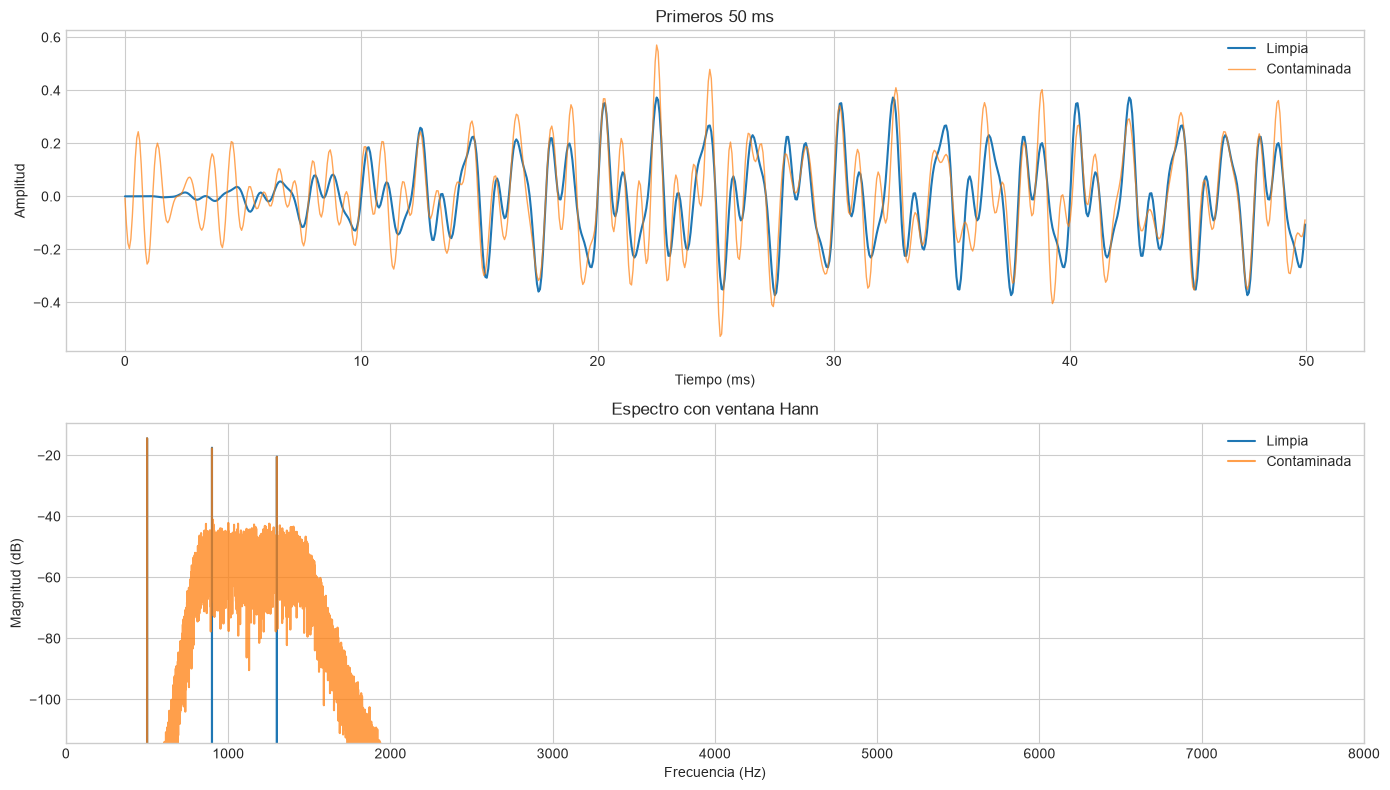

In [10]:
if FS < 2*max(FRECUENCIAS_UTILES + [FRECUENCIA_INTERFERENCIA, BANDA_RUIDO[1]]):
    raise ValueError('La configuración viola Nyquist. Aumente FS o reduzca las frecuencias.')

t = np.arange(int(FS*DURACION))/FS
clean = generar_limpia(TIPO_SENAL,t,FRECUENCIAS_UTILES,AMPLITUDES_UTILES,FASES_UTILES_GRADOS,rng)
clean = fade(clean,FS,FADE_MS)
noise_raw = generar_ruido(TIPO_RUIDO,t,FS,FRECUENCIA_INTERFERENCIA,BANDA_RUIDO,NUM_IMPULSOS,rng)
noise = escalar_ruido_para_snr(clean,noise_raw,SNR_OBJETIVO_DB)
noisy = clean + noise
[clean, noise, noisy], gain = normalizar_conjunto(clean,noise,noisy,peak=PICO_MAXIMO)
snr_real = snr_db(clean,noisy)
print(f'Muestras: {len(t):,} | SNR obtenida: {snr_real:.3f} dB | Ganancia común: {gain:.5f}')

view = min(len(t),int(.05*FS))
f1,m1 = espectro(clean,FS); f2,m2 = espectro(noisy,FS)
fig,ax = plt.subplots(2,1,figsize=(14,8))
ax[0].plot(t[:view]*1000,clean[:view],label='Limpia',lw=1.5)
ax[0].plot(t[:view]*1000,noisy[:view],label='Contaminada',alpha=.7,lw=1)
ax[0].set(xlabel='Tiempo (ms)',ylabel='Amplitud',title='Primeros 50 ms'); ax[0].legend()
ax[1].plot(f1,m1,label='Limpia'); ax[1].plot(f2,m2,label='Contaminada',alpha=.75)
ax[1].set_xlim(0,FS/2); ax[1].set_ylim(max(-120,np.max(m2)-100),np.max(m2)+5)
ax[1].set(xlabel='Frecuencia (Hz)',ylabel='Magnitud (dB)',title='Espectro con ventana Hann'); ax[1].legend()
plt.tight_layout(); plt.show()

## 5. Escucha
La referencia limpia se incluye para evaluación docente. Para la defensa puede reproducirse únicamente la señal contaminada hacia el ADC del sistema.

In [11]:
print('Referencia limpia')
display(Audio(clean,rate=FS,normalize=False))
print('Entrada contaminada para el sistema')
display(Audio(noisy,rate=FS,normalize=False))

Referencia limpia


Entrada contaminada para el sistema


## 6. Exportación
Crea archivos PCM mono de 16 bits. Todos usan la misma ganancia, por lo que las relaciones de amplitud y la SNR se conservan. El JSON permite repetir y auditar la prueba.

In [12]:
if CARPETA_SALIDA.exists(): shutil.rmtree(CARPETA_SALIDA)
CARPETA_SALIDA.mkdir(parents=True)
def pcm16(x): return np.int16(np.clip(x,-1,1)*32767)
wavfile.write(CARPETA_SALIDA/'01_referencia_limpia.wav',FS,pcm16(clean))
wavfile.write(CARPETA_SALIDA/'02_ruido.wav',FS,pcm16(noise))
wavfile.write(CARPETA_SALIDA/'03_entrada_contaminada.wav',FS,pcm16(noisy))
np.savetxt(CARPETA_SALIDA/'muestras_referencia.csv',np.column_stack([t,clean,noise,noisy]),
           delimiter=',',header='tiempo_s,limpia,ruido,contaminada',comments='')
metadata = {
 'nombre_prueba':NOMBRE_PRUEBA,'modo':MODO,'semilla':int(SEMILLA),'fs_Hz':int(FS),
 'duracion_s':float(DURACION),'tipo_senal':TIPO_SENAL,'frecuencias_utiles_Hz':[float(v) for v in FRECUENCIAS_UTILES],
 'amplitudes_utiles':[float(v) for v in AMPLITUDES_UTILES],'fases_grados':[float(v) for v in FASES_UTILES_GRADOS],
 'tipo_ruido':TIPO_RUIDO,'snr_objetivo_dB':float(SNR_OBJETIVO_DB),'snr_obtenida_dB':float(snr_real),
 'frecuencia_interferencia_Hz':float(FRECUENCIA_INTERFERENCIA),'banda_ruido_Hz':[float(v) for v in BANDA_RUIDO],
 'numero_impulsos':int(NUM_IMPULSOS),'pico_maximo':float(PICO_MAXIMO),'ganancia_comun':float(gain)
}
with open(CARPETA_SALIDA/'metadatos_prueba.json','w',encoding='utf-8') as f: json.dump(metadata,f,indent=2,ensure_ascii=False)
with open(CARPETA_SALIDA/'LEAME.txt','w',encoding='utf-8') as f:
    f.write('03_entrada_contaminada.wav: señal que se aplica al sistema.\n01_referencia_limpia.wav: referencia reservada para calcular métricas.\n02_ruido.wav: componente de ruido aislada.\n')
zip_path = CARPETA_SALIDA.parent/f'{NOMBRE_PRUEBA}.zip'
if zip_path.exists(): zip_path.unlink()
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as z:
    for p in CARPETA_SALIDA.iterdir(): z.write(p,arcname=p.name)
print(f'Archivos exportados en: {CARPETA_SALIDA}')
print(f'ZIP para descargar: {zip_path}')
display(metadata)

PermissionError: [WinError 5] Acceso denegado: 'caso_3'

## Uso sugerido durante la defensa
1. Defina una semilla distinta por grupo y ejecute todo el notebook.
2. Conserve `01_referencia_limpia.wav` y `metadatos_prueba.json` como información docente.
3. Reproduzca `03_entrada_contaminada.wav` hacia el ADC, comenzando con volumen bajo.
4. Solicite al grupo diagnosticar el ruido, ajustar su sistema y mostrar ambas salidas.
5. Capture las salidas y compárelas contra la referencia con MSE, SNR, energía, atenuación y latencia.
6. Si desea exactamente el mismo caso otra vez, reutilice la semilla y la configuración guardada.

# 7. Fundamentos, muestreo y FFT

Esta sección contiene los experimentos numéricos correspondientes al apartado 2.1 de la Tarea 1.

## 7.1 DFT directa y FFT


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Ejemplo numérico: DFT directa vs FFT
# ============================================================

x = np.array([1.0, 0.0, -1.0, 0.0])
N = len(x)

def dft_directa(x):
    N = len(x)
    X = np.zeros(N, dtype=complex)

    for k in range(N):
        for n in range(N):
            X[k] += x[n] * np.exp(
                -1j * 2 * np.pi * k * n / N
            )

    return X

X_dft = dft_directa(x)
X_fft = np.fft.fft(x)

print("Señal x[n]:")
print(x)

print("\nDFT directa:")
print(np.round(X_dft, 6))

print("\nFFT:")
print(np.round(X_fft, 6))

print("\nDiferencia máxima:")
print(np.max(np.abs(X_dft - X_fft)))

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Magnitud y fase del ejemplo
# ============================================================

magnitud = np.abs(X_dft)
fase = np.angle(X_dft)

# Si la magnitud es prácticamente cero,
# la fase no tiene significado físico útil.
fase[magnitud < 1e-10] = 0.0

k = np.arange(N)

fig, ax = plt.subplots(
    2,
    1,
    figsize=(8, 6)
)

ax[0].stem(
    k,
    magnitud
)

ax[0].set_title(
    "Magnitud de la DFT"
)

ax[0].set_xlabel(
    "Bin k"
)

ax[0].set_ylabel(
    "|X[k]|"
)

ax[0].grid(True)


ax[1].stem(
    k,
    fase
)

ax[1].set_title(
    "Fase de la DFT"
)

ax[1].set_xlabel(
    "Bin k"
)

ax[1].set_ylabel(
    "Fase (rad)"
)

ax[1].grid(True)


plt.tight_layout()

ruta = (
    "/kaggle/working/"
    "dft_ejemplo_magnitud_fase.png"
)

plt.savefig(
    ruta,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Figura guardada en:",
    ruta
)

## 7.2 Resolución frecuencial, latencia y memoria


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Resolución frecuencial, duración de bloque y memoria
# ============================================================

fs = 16000  # Hz

tamanos_bloque = np.array([
    128,
    256,
    512,
    1024,
    2048,
    4096
])

duraciones = tamanos_bloque / fs

delta_f = fs / tamanos_bloque

# Memoria aproximada para un bloque real float32
bytes_por_muestra = 4

memoria_bytes = (
    tamanos_bloque *
    bytes_por_muestra
)

memoria_kb = (
    memoria_bytes / 1024
)

print(
    "fs =",
    fs,
    "Hz"
)

print()
print(
    "N\tT (ms)\tΔf (Hz)\tMemoria float32 (kB)"
)

for N, T, df, mem in zip(
    tamanos_bloque,
    duraciones,
    delta_f,
    memoria_kb
):
    print(
        f"{N}\t"
        f"{T*1000:.2f}\t"
        f"{df:.3f}\t"
        f"{mem:.2f}"
    )

In [ ]:
fig, ax1 = plt.subplots(
    figsize=(8, 5)
)

ax1.plot(
    tamanos_bloque,
    delta_f,
    marker="o"
)

ax1.set_xlabel(
    "Tamaño de bloque N"
)

ax1.set_ylabel(
    "Resolución frecuencial Δf (Hz)"
)

ax1.set_title(
    "Compromiso entre tamaño de bloque y resolución frecuencial"
)

ax1.grid(True)

plt.tight_layout()

ruta = (
    "/kaggle/working/"
    "resolucion_frecuencial.png"
)

plt.savefig(
    ruta,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Figura guardada en:",
    ruta
)

## 7.3 Fuga espectral y comparación de ventanas

Se comparan dos tonos con los mismos parámetros de muestreo:

- un tono alineado exactamente con un bin de la DFT;
- un tono situado a la mitad entre dos bins.

Para ambos casos se comparan las ventanas rectangular y Hann.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Parámetros
# ============================================================

fs = 16000
N = 1024

delta_f = fs / N

k_bin = 64

f_alineada = k_bin * delta_f
f_intermedia = (k_bin + 0.5) * delta_f

n = np.arange(N)
t = n / fs

print(f"fs = {fs} Hz")
print(f"N = {N}")
print(f"Δf = {delta_f:.3f} Hz")
print(f"Tono alineado = {f_alineada:.4f} Hz")
print(f"Tono entre bins = {f_intermedia:.4f} Hz")

In [ ]:
# ============================================================
# Señales
# ============================================================

x_alineada = np.sin(
    2 * np.pi * f_alineada * t
)

x_intermedia = np.sin(
    2 * np.pi * f_intermedia * t
)

# Ventanas
ventana_rectangular = np.ones(N)
ventana_hann = np.hanning(N)

# Señales con ventana
x_alineada_rect = (
    x_alineada * ventana_rectangular
)

x_alineada_hann = (
    x_alineada * ventana_hann
)

x_intermedia_rect = (
    x_intermedia * ventana_rectangular
)

x_intermedia_hann = (
    x_intermedia * ventana_hann
)

In [ ]:
# ============================================================
# Espectro para visualización
# ============================================================

N_FFT = 16384

def calcular_espectro(x, N_fft=N_FFT):

    X = np.fft.rfft(
        x,
        n=N_fft
    )

    frecuencias = np.fft.rfftfreq(
        N_fft,
        d=1/fs
    )

    magnitud = np.abs(X)

    # Normalización respecto al máximo
    magnitud /= np.max(magnitud)

    magnitud_db = 20 * np.log10(
        np.maximum(
            magnitud,
            1e-12
        )
    )

    fase = np.angle(X)

    return (
        frecuencias,
        magnitud_db,
        fase
    )


f, mag_ar, fase_ar = calcular_espectro(
    x_alineada_rect
)

_, mag_ah, fase_ah = calcular_espectro(
    x_alineada_hann
)

_, mag_ir, fase_ir = calcular_espectro(
    x_intermedia_rect
)

_, mag_ih, fase_ih = calcular_espectro(
    x_intermedia_hann
)

In [ ]:
fig, ax = plt.subplots(
    2,
    2,
    figsize=(12, 8)
)

casos = [
    (
        mag_ar,
        "Alineado - Rectangular"
    ),
    (
        mag_ah,
        "Alineado - Hann"
    ),
    (
        mag_ir,
        "Entre bins - Rectangular"
    ),
    (
        mag_ih,
        "Entre bins - Hann"
    )
]

for eje, (magnitud, titulo) in zip(
    ax.flat,
    casos
):
    eje.plot(
        f,
        magnitud
    )

    eje.set_xlim(
        850,
        1150
    )

    eje.set_ylim(
        -100,
        5
    )

    eje.set_title(
        titulo
    )

    eje.set_xlabel(
        "Frecuencia (Hz)"
    )

    eje.set_ylabel(
        "Magnitud (dB)"
    )

    eje.grid(True)

plt.tight_layout()

ruta = (
    "/kaggle/working/"
    "comparacion_ventanas_magnitud.png"
)

plt.savefig(
    ruta,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Figura guardada en:",
    ruta
)

In [ ]:
def fase_filtrada(
    fase,
    magnitud_db,
    umbral=-60
):
    salida = fase.copy()

    salida[
        magnitud_db < umbral
    ] = np.nan

    return salida


fase_ar_plot = fase_filtrada(
    fase_ar,
    mag_ar
)

fase_ah_plot = fase_filtrada(
    fase_ah,
    mag_ah
)

fase_ir_plot = fase_filtrada(
    fase_ir,
    mag_ir
)

fase_ih_plot = fase_filtrada(
    fase_ih,
    mag_ih
)

In [ ]:
fig, ax = plt.subplots(
    2,
    2,
    figsize=(12, 8)
)

casos_fase = [
    (
        fase_ar_plot,
        "Alineado - Rectangular"
    ),
    (
        fase_ah_plot,
        "Alineado - Hann"
    ),
    (
        fase_ir_plot,
        "Entre bins - Rectangular"
    ),
    (
        fase_ih_plot,
        "Entre bins - Hann"
    )
]

for eje, (fase, titulo) in zip(
    ax.flat,
    casos_fase
):
    eje.plot(
        f,
        fase
    )

    eje.set_xlim(
        850,
        1150
    )

    eje.set_ylim(
        -np.pi,
        np.pi
    )

    eje.set_title(
        titulo
    )

    eje.set_xlabel(
        "Frecuencia (Hz)"
    )

    eje.set_ylabel(
        "Fase (rad)"
    )

    eje.grid(True)

plt.tight_layout()

ruta = (
    "/kaggle/working/"
    "comparacion_ventanas_fase.png"
)

plt.savefig(
    ruta,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Figura guardada en:",
    ruta
)

## 7.4 Simetría conjugada de la DFT

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Parámetros
# ============================================================

fs = 16000
N = 1024

n = np.arange(N)
t = n / fs

# Señal real compuesta por dos tonos
x = (
    np.sin(2 * np.pi * 1000 * t)
    +
    0.6 * np.sin(2 * np.pi * 2500 * t)
)

# DFT mediante FFT
X = np.fft.fft(x)

print("fs =", fs, "Hz")
print("N =", N)
print("Señal real:", np.isrealobj(x))

In [ ]:
# ============================================================
# Verificación de simetría conjugada
# ============================================================

errores = []

for k in range(1, N):
    error = np.abs(
        X[k] - np.conj(X[N - k])
    )

    errores.append(error)

error_maximo = np.max(errores)

print(
    "Error máximo de simetría conjugada:",
    error_maximo
)

In [ ]:
frecuencias = np.fft.fftfreq(
    N,
    d=1/fs
)

magnitud = np.abs(X)
fase = np.angle(X)

fig, ax = plt.subplots(
    2,
    1,
    figsize=(10, 7)
)

ax[0].plot(
    frecuencias,
    magnitud
)

ax[0].set_title(
    "Magnitud de la DFT de una señal real"
)

ax[0].set_xlabel(
    "Frecuencia (Hz)"
)

ax[0].set_ylabel(
    "|X[k]|"
)

ax[0].grid(True)


ax[1].plot(
    frecuencias,
    fase
)

ax[1].set_title(
    "Fase de la DFT"
)

ax[1].set_xlabel(
    "Frecuencia (Hz)"
)

ax[1].set_ylabel(
    "Fase (rad)"
)

ax[1].grid(True)


plt.tight_layout()

ruta = (
    "/kaggle/working/"
    "simetria_conjugada_espectro.png"
)

plt.savefig(
    ruta,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Figura guardada en:",
    ruta
)

In [ ]:
# ============================================================
# Modificación incorrecta:
# romper simetría conjugada
# ============================================================

X_incorrecto = X.copy()

# Bin correspondiente a 1000 Hz
k_objetivo = int(
    1000 / (fs / N)
)

print(
    "Bin objetivo:",
    k_objetivo
)

# Reducimos solo un lado del espectro
X_incorrecto[k_objetivo] *= 0.2

# IFFT
x_incorrecta = np.fft.ifft(
    X_incorrecto
)

print(
    "Máxima parte imaginaria con simetría rota:",
    np.max(
        np.abs(
            np.imag(x_incorrecta)
        )
    )
)

In [ ]:
# ============================================================
# Modificación correcta:
# preservar simetría conjugada
# ============================================================

X_correcto = X.copy()

X_correcto[k_objetivo] *= 0.2

X_correcto[N - k_objetivo] = np.conj(
    X_correcto[k_objetivo]
)

x_correcta = np.fft.ifft(
    X_correcto
)

print(
    "Máxima parte imaginaria preservando simetría:",
    np.max(
        np.abs(
            np.imag(x_correcta)
        )
    )
)

In [ ]:
fig, ax = plt.subplots(
    2,
    1,
    figsize=(10, 7)
)

ax[0].plot(
    t[:200],
    np.real(
        x_incorrecta[:200]
    ),
    label="Parte real"
)

ax[0].plot(
    t[:200],
    np.imag(
        x_incorrecta[:200]
    ),
    label="Parte imaginaria"
)

ax[0].set_title(
    "IFFT con simetría conjugada rota"
)

ax[0].set_xlabel(
    "Tiempo (s)"
)

ax[0].set_ylabel(
    "Amplitud"
)

ax[0].legend()
ax[0].grid(True)


ax[1].plot(
    t[:200],
    np.real(
        x_correcta[:200]
    ),
    label="Parte real"
)

ax[1].plot(
    t[:200],
    np.imag(
        x_correcta[:200]
    ),
    label="Parte imaginaria"
)

ax[1].set_title(
    "IFFT preservando simetría conjugada"
)

ax[1].set_xlabel(
    "Tiempo (s)"
)

ax[1].set_ylabel(
    "Amplitud"
)

ax[1].legend()
ax[1].grid(True)


plt.tight_layout()

ruta = (
    "/kaggle/working/"
    "ifft_simetria_conjugada.png"
)

plt.savefig(
    ruta,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Figura guardada en:",
    ruta
)

# 8. Caracterización de señales

## 8.1 Caracterización adicional del Caso 1

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Caso 1 - Magnitud y fase
# Usa las variables originales del notebook:
# clean, noise, noisy y FS
# ============================================================

N_total = len(clean)

ventana = np.hanning(N_total)

X_limpia = np.fft.rfft(clean * ventana)
X_ruido = np.fft.rfft(noise * ventana)
X_contaminada = np.fft.rfft(noisy * ventana)

frecuencias = np.fft.rfftfreq(
    N_total,
    d=1 / FS
)

mag_limpia = np.abs(X_limpia)
mag_ruido = np.abs(X_ruido)
mag_contaminada = np.abs(X_contaminada)

fase_limpia = np.angle(X_limpia)
fase_ruido = np.angle(X_ruido)
fase_contaminada = np.angle(X_contaminada)

# Mostrar fase solo donde la magnitud sea significativa
umbral_limpia = 1e-6 * np.max(mag_limpia)
umbral_contaminada = 1e-6 * np.max(mag_contaminada)

fase_limpia_plot = np.where(
    mag_limpia > umbral_limpia,
    fase_limpia,
    np.nan
)

fase_contaminada_plot = np.where(
    mag_contaminada > umbral_contaminada,
    fase_contaminada,
    np.nan
)

# Magnitud normalizada en dB
mag_limpia_db = 20 * np.log10(
    np.maximum(
        mag_limpia / np.max(mag_limpia),
        1e-12
    )
)

mag_contaminada_db = 20 * np.log10(
    np.maximum(
        mag_contaminada / np.max(mag_contaminada),
        1e-12
    )
)

fig, ax = plt.subplots(
    2,
    1,
    figsize=(11, 8)
)

ax[0].plot(
    frecuencias,
    mag_limpia_db,
    label="Limpia"
)

ax[0].plot(
    frecuencias,
    mag_contaminada_db,
    label="Contaminada",
    alpha=0.8
)

ax[0].set_xlim(0, 2500)
ax[0].set_ylim(-100, 5)
ax[0].set_title("Caso 1 - Magnitud")
ax[0].set_xlabel("Frecuencia (Hz)")
ax[0].set_ylabel("Magnitud (dB)")
ax[0].legend()
ax[0].grid(True)

ax[1].plot(
    frecuencias,
    fase_limpia_plot,
    label="Limpia"
)

ax[1].plot(
    frecuencias,
    fase_contaminada_plot,
    label="Contaminada",
    alpha=0.8
)

ax[1].set_xlim(0, 2500)
ax[1].set_ylim(-np.pi, np.pi)
ax[1].set_title("Caso 1 - Fase")
ax[1].set_xlabel("Frecuencia (Hz)")
ax[1].set_ylabel("Fase (rad)")
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()

ruta = "/kaggle/working/caso_1_magnitud_fase.png"

plt.savefig(
    ruta,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figura guardada en:", ruta)

In [ ]:
# ============================================================
# Caso 1 - Distribución de energía por bandas
# ============================================================

def energia_banda(
    X,
    frecuencias,
    f_min,
    f_max
):
    mascara = (
        (frecuencias >= f_min)
        &
        (frecuencias < f_max)
    )

    return np.sum(
        np.abs(X[mascara]) ** 2
    )


bandas = [
    (0, 700),
    (700, 1100),
    (1100, 1500),
    (1500, 2100),
    (2100, 8000)
]

energia_total = np.sum(
    np.abs(X_contaminada) ** 2
)

porcentajes = []
etiquetas = []

print("Distribución de energía - Caso 1")
print()

for f_min, f_max in bandas:

    energia = energia_banda(
        X_contaminada,
        frecuencias,
        f_min,
        f_max
    )

    porcentaje = (
        100 * energia / energia_total
    )

    porcentajes.append(
        porcentaje
    )

    etiquetas.append(
        f"{f_min}-{f_max}"
    )

    print(
        f"{f_min:4d}-{f_max:4d} Hz: "
        f"{porcentaje:.2f} %"
    )

In [ ]:
plt.figure(
    figsize=(9, 5)
)

plt.bar(
    etiquetas,
    porcentajes
)

plt.title(
    "Caso 1 - Distribución de energía por bandas"
)

plt.xlabel(
    "Banda de frecuencia (Hz)"
)

plt.ylabel(
    "Energía (%)"
)

plt.grid(
    axis="y"
)

plt.tight_layout()

ruta = (
    "/kaggle/working/"
    "caso_1_energia_bandas.png"
)

plt.savefig(
    ruta,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Figura guardada en:",
    ruta
)

## 8.2 Caracterización adicional del Caso 2

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Caso 2 - Magnitud y fase
# ============================================================

N_total = len(clean)

ventana = np.hanning(N_total)

X_limpia = np.fft.rfft(clean * ventana)
X_ruido = np.fft.rfft(noise * ventana)
X_contaminada = np.fft.rfft(noisy * ventana)

frecuencias = np.fft.rfftfreq(
    N_total,
    d=1 / FS
)

mag_limpia = np.abs(X_limpia)
mag_ruido = np.abs(X_ruido)
mag_contaminada = np.abs(X_contaminada)

fase_limpia = np.angle(X_limpia)
fase_contaminada = np.angle(X_contaminada)

umbral_limpia = 1e-6 * np.max(mag_limpia)
umbral_contaminada = 1e-6 * np.max(mag_contaminada)

fase_limpia_plot = np.where(
    mag_limpia > umbral_limpia,
    fase_limpia,
    np.nan
)

fase_contaminada_plot = np.where(
    mag_contaminada > umbral_contaminada,
    fase_contaminada,
    np.nan
)

mag_limpia_db = 20 * np.log10(
    np.maximum(
        mag_limpia / np.max(mag_limpia),
        1e-12
    )
)

mag_contaminada_db = 20 * np.log10(
    np.maximum(
        mag_contaminada / np.max(mag_contaminada),
        1e-12
    )
)

fig, ax = plt.subplots(
    2,
    1,
    figsize=(11, 8)
)

ax[0].plot(
    frecuencias,
    mag_limpia_db,
    label="Limpia"
)

ax[0].plot(
    frecuencias,
    mag_contaminada_db,
    label="Contaminada",
    alpha=0.8
)

ax[0].set_xlim(0, 8000)
ax[0].set_ylim(-100, 5)
ax[0].set_title("Caso 2 - Magnitud")
ax[0].set_xlabel("Frecuencia (Hz)")
ax[0].set_ylabel("Magnitud (dB)")
ax[0].legend()
ax[0].grid(True)

ax[1].plot(
    frecuencias,
    fase_limpia_plot,
    label="Limpia"
)

ax[1].plot(
    frecuencias,
    fase_contaminada_plot,
    label="Contaminada",
    alpha=0.8
)

ax[1].set_xlim(0, 8000)
ax[1].set_ylim(-np.pi, np.pi)
ax[1].set_title("Caso 2 - Fase")
ax[1].set_xlabel("Frecuencia (Hz)")
ax[1].set_ylabel("Fase (rad)")
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()

ruta = "/kaggle/working/caso_2_magnitud_fase.png"

plt.savefig(
    ruta,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figura guardada en:", ruta)

In [ ]:
def energia_banda(
    X,
    frecuencias,
    f_min,
    f_max
):
    mascara = (
        (frecuencias >= f_min)
        &
        (frecuencias < f_max)
    )

    return np.sum(
        np.abs(X[mascara]) ** 2
    )


bandas = [
    (0, 700),
    (700, 1100),
    (1100, 1500),
    (1500, 2100),
    (2100, 8000)
]

energia_total = np.sum(
    np.abs(X_contaminada) ** 2
)

porcentajes = []
etiquetas = []

print("Distribución de energía - Caso 2")
print()

for f_min, f_max in bandas:

    energia = energia_banda(
        X_contaminada,
        frecuencias,
        f_min,
        f_max
    )

    porcentaje = (
        100 * energia / energia_total
    )

    porcentajes.append(
        porcentaje
    )

    etiquetas.append(
        f"{f_min}-{f_max}"
    )

    print(
        f"{f_min:4d}-{f_max:4d} Hz: "
        f"{porcentaje:.2f} %"
    )

In [ ]:
plt.figure(
    figsize=(9, 5)
)

plt.bar(
    etiquetas,
    porcentajes
)

plt.title(
    "Caso 2 - Distribución de energía por bandas"
)

plt.xlabel(
    "Banda de frecuencia (Hz)"
)

plt.ylabel(
    "Energía (%)"
)

plt.grid(
    axis="y"
)

plt.tight_layout()

ruta = (
    "/kaggle/working/"
    "caso_2_energia_bandas.png"
)

plt.savefig(
    ruta,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Figura guardada en:",
    ruta
)

## 8.3 Caracterización adicional del Caso 3

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Caso 3 - Magnitud y fase
# ============================================================

N_total = len(clean)

ventana = np.hanning(N_total)

X_limpia = np.fft.rfft(clean * ventana)
X_ruido = np.fft.rfft(noise * ventana)
X_contaminada = np.fft.rfft(noisy * ventana)

frecuencias = np.fft.rfftfreq(
    N_total,
    d=1 / FS
)

mag_limpia = np.abs(X_limpia)
mag_ruido = np.abs(X_ruido)
mag_contaminada = np.abs(X_contaminada)

fase_limpia = np.angle(X_limpia)
fase_contaminada = np.angle(X_contaminada)

# Mostrar fase únicamente donde la magnitud sea significativa
umbral_limpia = 1e-6 * np.max(mag_limpia)
umbral_contaminada = 1e-6 * np.max(mag_contaminada)

fase_limpia_plot = np.where(
    mag_limpia > umbral_limpia,
    fase_limpia,
    np.nan
)

fase_contaminada_plot = np.where(
    mag_contaminada > umbral_contaminada,
    fase_contaminada,
    np.nan
)

# Magnitud normalizada en dB
mag_limpia_db = 20 * np.log10(
    np.maximum(
        mag_limpia / np.max(mag_limpia),
        1e-12
    )
)

mag_contaminada_db = 20 * np.log10(
    np.maximum(
        mag_contaminada / np.max(mag_contaminada),
        1e-12
    )
)

fig, ax = plt.subplots(
    2,
    1,
    figsize=(11, 8)
)

# Magnitud
ax[0].plot(
    frecuencias,
    mag_limpia_db,
    label="Limpia"
)

ax[0].plot(
    frecuencias,
    mag_contaminada_db,
    label="Contaminada",
    alpha=0.8
)

ax[0].set_xlim(0, 2500)
ax[0].set_ylim(-100, 5)
ax[0].set_title("Caso 3 - Magnitud")
ax[0].set_xlabel("Frecuencia (Hz)")
ax[0].set_ylabel("Magnitud (dB)")
ax[0].legend()
ax[0].grid(True)

# Fase
ax[1].plot(
    frecuencias,
    fase_limpia_plot,
    label="Limpia"
)

ax[1].plot(
    frecuencias,
    fase_contaminada_plot,
    label="Contaminada",
    alpha=0.8
)

ax[1].set_xlim(0, 2500)
ax[1].set_ylim(-np.pi, np.pi)
ax[1].set_title("Caso 3 - Fase")
ax[1].set_xlabel("Frecuencia (Hz)")
ax[1].set_ylabel("Fase (rad)")
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()

ruta = "/kaggle/working/caso_3_magnitud_fase.png"

plt.savefig(
    ruta,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figura guardada en:", ruta)

In [ ]:
# ============================================================
# Caso 3 - Distribución de energía por bandas
# ============================================================

def energia_banda(
    X,
    frecuencias,
    f_min,
    f_max
):
    mascara = (
        (frecuencias >= f_min)
        &
        (frecuencias < f_max)
    )

    return np.sum(
        np.abs(X[mascara]) ** 2
    )


bandas = [
    (0, 700),
    (700, 800),
    (800, 1100),
    (1100, 1500),
    (1500, 2100),
    (2100, 8000)
]

energia_total = np.sum(
    np.abs(X_contaminada) ** 2
)

porcentajes = []
etiquetas = []

print("Distribución de energía - Caso 3")
print()

for f_min, f_max in bandas:

    energia = energia_banda(
        X_contaminada,
        frecuencias,
        f_min,
        f_max
    )

    porcentaje = (
        100 * energia / energia_total
    )

    porcentajes.append(
        porcentaje
    )

    etiquetas.append(
        f"{f_min}-{f_max}"
    )

    print(
        f"{f_min:4d}-{f_max:4d} Hz: "
        f"{porcentaje:.2f} %"
    )

In [ ]:
plt.figure(
    figsize=(10, 5)
)

plt.bar(
    etiquetas,
    porcentajes
)

plt.title(
    "Caso 3 - Distribución de energía por bandas"
)

plt.xlabel(
    "Banda de frecuencia (Hz)"
)

plt.ylabel(
    "Energía (%)"
)

plt.grid(
    axis="y"
)

plt.tight_layout()

ruta = (
    "/kaggle/working/"
    "caso_3_energia_bandas.png"
)

plt.savefig(
    ruta,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Figura guardada en:",
    ruta
)

# 9. Diseño y comparación FIR/IIR

En esta sección se diseña un filtro FIR candidato y se compara con el filtro IIR Butterworth utilizado en el sistema embebido.

El objetivo es utilizar especificaciones comunes para ambos métodos y evaluar su respuesta en frecuencia, retardo, costo computacional y memoria requerida.

El sistema trabaja con una frecuencia de muestreo de:

$$
f_s = 16000\ \mathrm{Hz}
$$

y una banda útil que contiene principalmente componentes hasta aproximadamente 1300 Hz.

In [48]:
# =====================================================
# IMPORTAR MÓDULO DE FILTROS
# =====================================================

from src.filtros import (
    FS,
    F_PASS,
    F_STOP,
    ATENUACION_FIR_DB,
    ORDEN_IIR,
    FC_IIR,
    disenar_fir,
    respuesta_fir,
    retardo_grupo_fir,
    disenar_iir,
    respuesta_iir,
    estimar_costo_fir,
    estimar_costo_iir,
    estimar_memoria_fir,
    estimar_memoria_iir,
)

## 9.1 Especificaciones comunes

Para permitir una comparación directa entre el FIR candidato y el IIR utilizado en hardware, se adoptan las siguientes especificaciones:

- Frecuencia de muestreo: $f_s = 16000\ \mathrm{Hz}$.
- Fin de banda útil: $f_p = 1300\ \mathrm{Hz}$.
- Inicio de banda de rechazo: $f_{\mathrm{stop}} = 1800\ \mathrm{Hz}$.
- Banda de transición: 1300--1800 Hz.
- Atenuación objetivo en banda de rechazo para el FIR: aproximadamente 40 dB.

In [49]:
ANCHO_TRANSICION_HZ = F_STOP - F_PASS

ANCHO_TRANSICION_NORMALIZADO = (
    ANCHO_TRANSICION_HZ
    / (FS / 2)
)

print("Frecuencia de muestreo:", FS, "Hz")
print("Fin banda útil:", F_PASS, "Hz")
print("Inicio banda rechazo:", F_STOP, "Hz")
print("Ancho transición:", ANCHO_TRANSICION_HZ, "Hz")
print(
    "Ancho transición normalizado:",
    ANCHO_TRANSICION_NORMALIZADO
)

Frecuencia de muestreo: 16000 Hz
Fin banda útil: 1300 Hz
Inicio banda rechazo: 1800 Hz
Ancho transición: 500 Hz
Ancho transición normalizado: 0.0625


## 9.2 Diseño del FIR candidato

Se propone un filtro FIR pasa-bajos diseñado mediante una ventana Kaiser.

La ventana Kaiser permite controlar el compromiso entre el ancho de la banda de transición y la atenuación de los lóbulos laterales.

El orden se estima automáticamente a partir del ancho de transición:

$$
\Delta f = 1800 - 1300 = 500\ \mathrm{Hz}
$$

y una atenuación objetivo de aproximadamente 40 dB.

Para obtener fase lineal se utiliza un número impar de coeficientes, correspondiente a un FIR tipo I.

In [50]:
# =====================================================
# DISEÑO FIR
# =====================================================

fir = disenar_fir()

coef_fir = fir["coeficientes"]
num_taps = fir["num_taps"]
orden_fir = fir["orden"]
beta = fir["beta"]
FC_FIR = fir["fc"]

print("Número de coeficientes:", num_taps)
print("Orden FIR:", orden_fir)
print("Beta Kaiser:", beta)
print("Frecuencia de corte de diseño:", FC_FIR, "Hz")

Número de coeficientes: 73
Orden FIR: 72
Beta Kaiser: 3.3953210522614574
Frecuencia de corte de diseño: 1550.0 Hz


In [51]:
print("Coeficientes FIR:\n")

for i, coef in enumerate(coef_fir):
    print(
        f"h[{i:02d}] = "
        f"{coef:.10e}"
    )

Coeficientes FIR:

h[00] = 1.0224586375e-04
h[01] = 9.9000035668e-04
h[02] = 1.7747997878e-03
h[03] = 2.0363818882e-03
h[04] = 1.4673008741e-03
h[05] = 5.6328471693e-05
h[06] = -1.8197610825e-03
h[07] = -3.4625215172e-03
h[08] = -4.0840188910e-03
h[09] = -3.1378350123e-03
h[10] = -6.2213576555e-04
h[11] = 2.7867415612e-03
h[12] = 5.8664929874e-03
h[13] = 7.2466999555e-03
h[14] = 5.9572345136e-03
h[15] = 1.9249328475e-03
h[16] = -3.8011523628e-03
h[17] = -9.2439361720e-03
h[18] = -1.2114126015e-02
h[19] = -1.0677872790e-02
h[20] = -4.5740550536e-03
h[21] = 4.7543504827e-03
h[22] = 1.4256549253e-02
h[23] = 2.0136951939e-02
h[24] = 1.9175821484e-02
h[25] = 1.0093450188e-02
h[26] = -5.5350637365e-03
h[27] = -2.3215375083e-02
h[28] = -3.6472145367e-02
h[29] = -3.8610615141e-02
h[30] = -2.4817797305e-02
h[31] = 6.0471453601e-03
h[32] = 5.0583245188e-02
h[33] = 1.0125952123e-01
h[34] = 1.4808262335e-01
h[35] = 1.8109421612e-01
h[36] = 1.9299075519e-01
h[37] = 1.8109421612e-01
h[38] = 1.480826

## 9.3 Respuesta en frecuencia del FIR

La respuesta en frecuencia permite verificar la conservación de la banda útil y la atenuación lograda en la banda de rechazo.

Se evalúan especialmente las frecuencias utilizadas durante las pruebas del sistema:

- 500 Hz
- 900 Hz
- 1000 Hz
- 1300 Hz
- 1500 Hz
- 1800 Hz
- 2000 Hz
- 2500 Hz

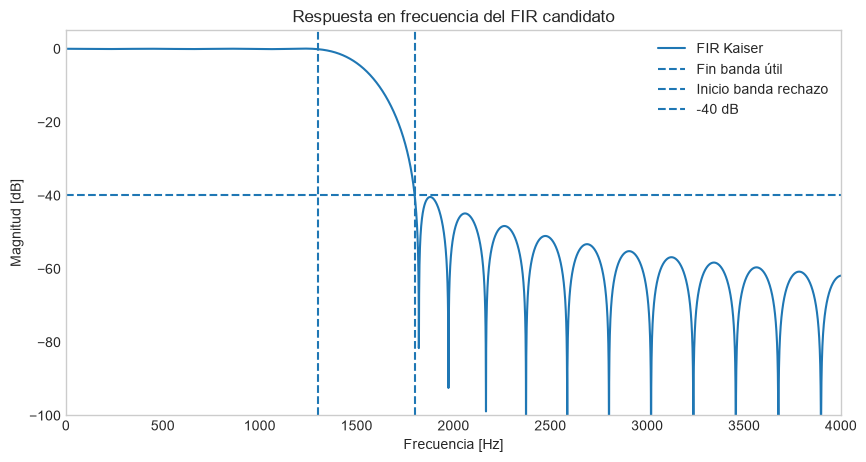

In [52]:
# =====================================================
# RESPUESTA FIR
# =====================================================

(
    freq_fir,
    H_fir,
    mag_fir_db,
    fase_fir
) = respuesta_fir(
    coef_fir
)

plt.figure(figsize=(10, 5))

plt.plot(
    freq_fir,
    mag_fir_db,
    label="FIR Kaiser"
)

plt.axvline(
    F_PASS,
    linestyle="--",
    label="Fin banda útil"
)

plt.axvline(
    F_STOP,
    linestyle="--",
    label="Inicio banda rechazo"
)

plt.axhline(
    -ATENUACION_FIR_DB,
    linestyle="--",
    label="-40 dB"
)

plt.xlim(0, 4000)
plt.ylim(-100, 5)

plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Magnitud [dB]")
plt.title(
    "Respuesta en frecuencia del FIR candidato"
)

plt.grid()
plt.legend()
plt.show()

In [53]:
frecuencias_prueba = [
    500,
    900,
    1000,
    1300,
    1500,
    1800,
    2000,
    2500
]

resultados_fir = []

for f in frecuencias_prueba:

    idx = np.argmin(
        np.abs(
            freq_fir - f
        )
    )

    valor_db = mag_fir_db[idx]

    resultados_fir.append(
        [f, valor_db]
    )

    print(
        f"{f:4d} Hz -> "
        f"{valor_db:8.3f} dB"
    )

 500 Hz ->   -0.015 dB
 900 Hz ->    0.002 dB
1000 Hz ->   -0.074 dB
1300 Hz ->   -0.105 dB
1500 Hz ->   -3.870 dB
1800 Hz ->  -39.945 dB
2000 Hz ->  -50.951 dB
2500 Hz ->  -51.675 dB


## 9.4 Fase y retardo de grupo

Una ventaja importante de los filtros FIR simétricos es que pueden presentar fase aproximadamente lineal.

Esto implica que las distintas componentes frecuenciales sufren prácticamente el mismo retardo temporal, reduciendo la distorsión de fase.

Para un FIR tipo I de orden $M$, el retardo de grupo ideal es:

$$
\tau_g = \frac{M}{2}
$$

muestras.

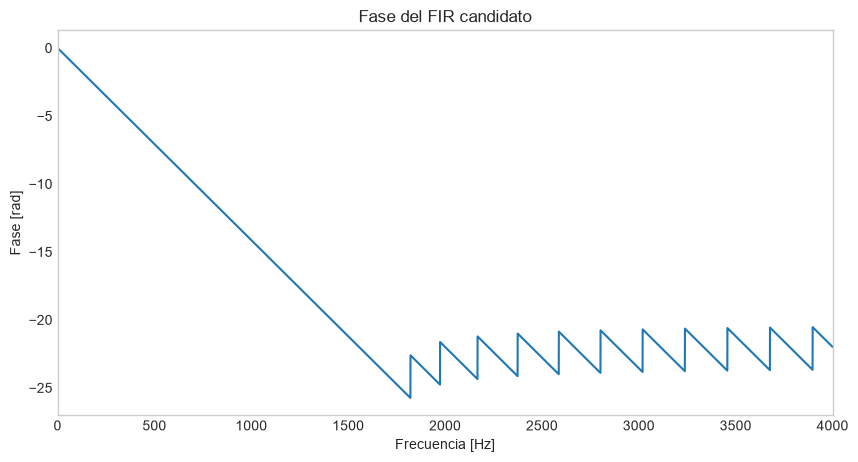

In [54]:
plt.figure(figsize=(10, 5))

plt.plot(
    freq_fir,
    fase_fir
)

plt.xlim(0, 4000)

plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Fase [rad]")
plt.title("Fase del FIR candidato")

plt.grid()
plt.show()

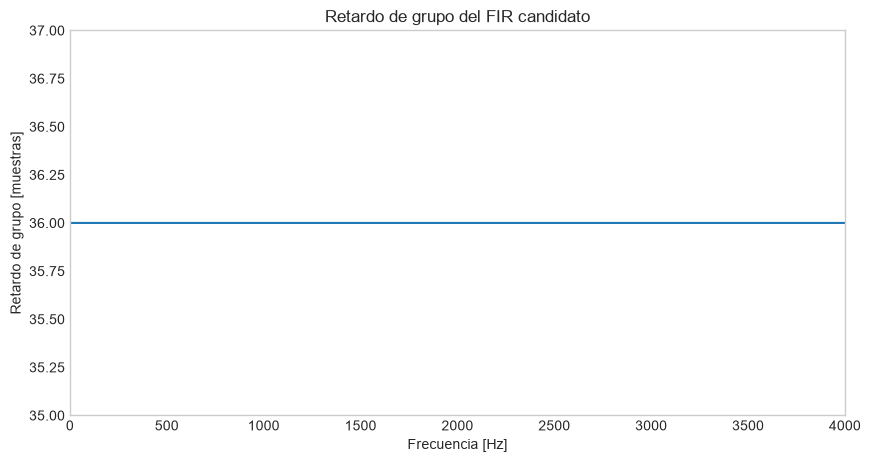

Retardo teórico: 36.0 muestras
Retardo teórico: 2.25 ms


In [55]:
# =====================================================
# RETARDO DE GRUPO FIR
# =====================================================

retardo_teorico_muestras = (
    orden_fir / 2
)

retardo_teorico_ms = (
    retardo_teorico_muestras
    / FS
    * 1000
)

freq_gd_fir, gd_fir = (
    retardo_grupo_fir(
        coef_fir
    )
)

plt.figure(figsize=(10, 5))

plt.plot(
    freq_gd_fir,
    gd_fir
)

plt.xlim(0, 4000)

plt.ylim(
    retardo_teorico_muestras - 1,
    retardo_teorico_muestras + 1
)

plt.xlabel("Frecuencia [Hz]")
plt.ylabel(
    "Retardo de grupo [muestras]"
)
plt.title(
    "Retardo de grupo del FIR candidato"
)

plt.grid()
plt.show()

print(
    "Retardo teórico:",
    retardo_teorico_muestras,
    "muestras"
)

print(
    "Retardo teórico:",
    retardo_teorico_ms,
    "ms"
)

## 9.5 Comparación FIR vs IIR

El filtro FIR candidato se compara contra el filtro IIR Butterworth de orden 12 utilizado en la implementación embebida.

El IIR fue implementado mediante seis secciones de segundo orden (SOS).

La comparación considera:

- magnitud;
- fase;
- retardo;
- costo computacional;
- memoria;
- conveniencia para tiempo real.

In [56]:
# =====================================================
# DISEÑO Y RESPUESTA IIR
# =====================================================

sos_iir = disenar_iir()

(
    freq_iir,
    H_iir,
    mag_iir_db,
    fase_iir
) = respuesta_iir(
    sos_iir
)

print(
    "Número de secciones SOS:",
    len(sos_iir)
)

print(
    "Orden IIR:",
    ORDEN_IIR
)

print(
    "Frecuencia de corte:",
    FC_IIR,
    "Hz"
)

Número de secciones SOS: 6
Orden IIR: 12
Frecuencia de corte: 1500 Hz


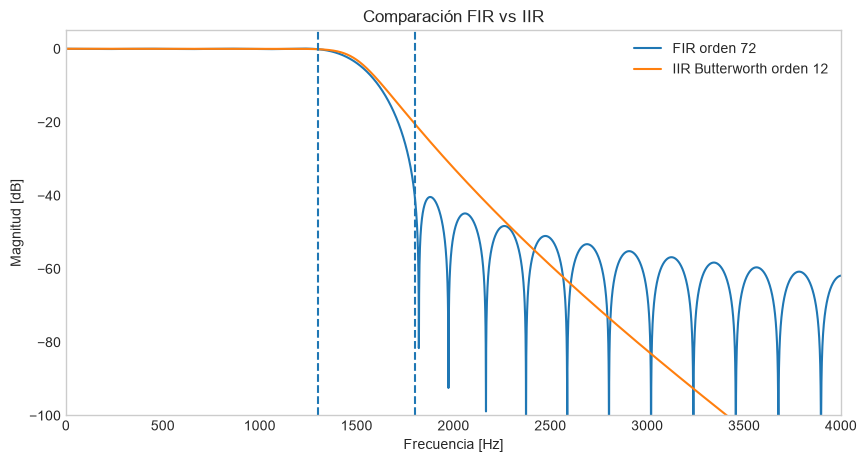

In [57]:
plt.figure(figsize=(10, 5))

plt.plot(
    freq_fir,
    mag_fir_db,
    label=f"FIR orden {orden_fir}"
)

plt.plot(
    freq_iir,
    mag_iir_db,
    label=f"IIR Butterworth orden {ORDEN_IIR}"
)

plt.axvline(
    F_PASS,
    linestyle="--"
)

plt.axvline(
    F_STOP,
    linestyle="--"
)

plt.xlim(0, 4000)
plt.ylim(-100, 5)

plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Magnitud [dB]")
plt.title("Comparación FIR vs IIR")

plt.grid()
plt.legend()
plt.show()

In [58]:
comparacion = []

for f in frecuencias_prueba:

    idx_fir = np.argmin(
        np.abs(
            freq_fir - f
        )
    )

    idx_iir = np.argmin(
        np.abs(
            freq_iir - f
        )
    )

    fir_db = mag_fir_db[
        idx_fir
    ]

    iir_db = mag_iir_db[
        idx_iir
    ]

    comparacion.append(
        [
            f,
            fir_db,
            iir_db
        ]
    )

    print(
        f"{f:4d} Hz | "
        f"FIR = {fir_db:8.3f} dB | "
        f"IIR = {iir_db:8.3f} dB"
    )

 500 Hz | FIR =   -0.015 dB | IIR =   -0.000 dB
 900 Hz | FIR =    0.002 dB | IIR =   -0.000 dB
1000 Hz | FIR =   -0.074 dB | IIR =   -0.000 dB
1300 Hz | FIR =   -0.105 dB | IIR =   -0.115 dB
1500 Hz | FIR =   -3.870 dB | IIR =   -3.010 dB
1800 Hz | FIR =  -39.945 dB | IIR =  -20.425 dB
2000 Hz | FIR =  -50.951 dB | IIR =  -32.471 dB
2500 Hz | FIR =  -51.675 dB | IIR =  -59.044 dB


## 9.6 Costo computacional y memoria

Además de la respuesta en frecuencia, la selección del filtro debe considerar los recursos requeridos por el microcontrolador.

El FIR requiere aproximadamente una multiplicación por coeficiente para cada muestra:

$$
N_{\mathrm{mult,FIR}}
=
N_{\mathrm{coef}}
$$

Para el IIR implementado mediante secciones SOS, cada biquad requiere aproximadamente cinco multiplicaciones por muestra.

También se estima la memoria requerida por los coeficientes y los estados internos utilizando representación `float32`.

In [59]:
costo_fir = estimar_costo_fir(
    num_taps
)

costo_iir = estimar_costo_iir(
    len(sos_iir)
)

print("FIR")
print(
    "Multiplicaciones/muestra:",
    costo_fir[
        "multiplicaciones_muestra"
    ]
)

print(
    "Sumas/muestra:",
    costo_fir[
        "sumas_muestra"
    ]
)

print()

print("IIR")
print(
    "Secciones SOS:",
    len(sos_iir)
)

print(
    "Multiplicaciones/muestra:",
    costo_iir[
        "multiplicaciones_muestra"
    ]
)

print()

print(
    "Relación FIR/IIR:",
    costo_fir[
        "multiplicaciones_muestra"
    ]
    / costo_iir[
        "multiplicaciones_muestra"
    ]
)

FIR
Multiplicaciones/muestra: 73
Sumas/muestra: 72

IIR
Secciones SOS: 6
Multiplicaciones/muestra: 30

Relación FIR/IIR: 2.433333333333333


In [60]:
print(
    "FIR multiplicaciones/s:",
    costo_fir[
        "multiplicaciones_segundo"
    ]
)

print(
    "IIR multiplicaciones/s:",
    costo_iir[
        "multiplicaciones_segundo"
    ]
)

FIR multiplicaciones/s: 1168000
IIR multiplicaciones/s: 480000


In [61]:
mem_fir = estimar_memoria_fir(
    num_taps
)

mem_iir = estimar_memoria_iir(
    len(sos_iir)
)

print("FIR:")
print(
    "Coeficientes:",
    mem_fir[
        "coeficientes_bytes"
    ],
    "bytes"
)

print(
    "Estados:",
    mem_fir[
        "estados_bytes"
    ],
    "bytes"
)

print(
    "Total:",
    mem_fir[
        "total_bytes"
    ],
    "bytes"
)

print()

print("IIR:")
print(
    "Coeficientes:",
    mem_iir[
        "coeficientes_bytes"
    ],
    "bytes"
)

print(
    "Estados:",
    mem_iir[
        "estados_bytes"
    ],
    "bytes"
)

print(
    "Total:",
    mem_iir[
        "total_bytes"
    ],
    "bytes"
)

print()

print(
    "Relación de memoria FIR/IIR:",
    mem_fir["total_bytes"]
    / mem_iir["total_bytes"]
)

FIR:
Coeficientes: 292 bytes
Estados: 288 bytes
Total: 580 bytes

IIR:
Coeficientes: 120 bytes
Estados: 48 bytes
Total: 168 bytes

Relación de memoria FIR/IIR: 3.4523809523809526


## 9.7 Selección final del filtro temporal

El filtro FIR candidato presenta fase aproximadamente lineal y retardo de grupo constante.

El filtro IIR Butterworth presenta una respuesta de fase no lineal, pero requiere un menor número de operaciones por muestra y una menor cantidad de memoria.

Debido a que el sistema debe operar en tiempo real y compartir los recursos del ESP32-S3 con la ruta espectral FFT/IFFT, se selecciona el filtro IIR Butterworth de orden 12 como implementación temporal final.

El FIR se conserva como candidato teórico de comparación.

# 10. Generación de señales P1–P5

En esta sección se generan las señales de referencia correspondientes a las pruebas P1--P5.

Cada prueba contiene una señal limpia, una componente de ruido o interferencia y una señal contaminada con SNR inicial controlada.

Las funciones de generación se encuentran implementadas en el módulo `src/senales.py`.

In [23]:
from src.senales import (
    FS as FS_PRUEBAS,
    N_BLOQUE,
    DURACION as DURACION_PRUEBA,
    SNR_OBJETIVO_DB,
    SEMILLAS,
    generar_p1,
    generar_p2,
    generar_p3,
    generar_p4,
    generar_p5,
    calcular_snr_db,
)

print(
    "fs =",
    FS_PRUEBAS,
    "Hz"
)

print(
    "N =",
    N_BLOQUE
)

print(
    "Duración =",
    DURACION_PRUEBA,
    "s"
)

print(
    "SNR objetivo =",
    SNR_OBJETIVO_DB,
    "dB"
)

fs = 16000 Hz
N = 1024
Duración = 6.0 s
SNR objetivo = 5.0 dB


## 10.1 P1 — Tono con interferencia sinusoidal separada

La señal útil corresponde a un tono de 1000 Hz y la interferencia sinusoidal se ubica en 2500 Hz.

In [24]:
limpia_p1, ruido_p1, contaminada_p1 = (
    generar_p1()
)

snr_p1 = calcular_snr_db(
    limpia_p1,
    contaminada_p1
)

print(
    "P1 -> SNR =",
    f"{snr_p1:.3f}",
    "dB"
)

P1 -> SNR = 5.000 dB


## 10.2 P2 — Tres tonos con ruido de alta frecuencia

La señal útil se compone de tonos en 500 Hz, 900 Hz y 1300 Hz.

La perturbación se concentra principalmente por encima de la banda útil.

In [25]:
limpia_p2, ruido_p2, contaminada_p2 = (
    generar_p2()
)

snr_p2 = calcular_snr_db(
    limpia_p2,
    contaminada_p2
)

print(
    "P2 -> SNR =",
    f"{snr_p2:.3f}",
    "dB"
)

P2 -> SNR = 5.000 dB


## 10.3 P3 — Señal arbitraria con ruido de banda ancha

Se utiliza una señal arbitraria sintética compuesta por varias componentes de baja frecuencia y amplitud variable.

La perturbación corresponde a ruido de banda ancha.

In [26]:
limpia_p3, ruido_p3, contaminada_p3 = (
    generar_p3()
)

snr_p3 = calcular_snr_db(
    limpia_p3,
    contaminada_p3
)

print(
    "P3 -> SNR =",
    f"{snr_p3:.3f}",
    "dB"
)

P3 -> SNR = 5.000 dB


## 10.4 P4 — Señal transitoria con ruido impulsivo

La señal útil corresponde a una componente transitoria de duración limitada.

La perturbación se genera mediante impulsos distribuidos durante la señal.

In [27]:
limpia_p4, ruido_p4, contaminada_p4 = (
    generar_p4()
)

snr_p4 = calcular_snr_db(
    limpia_p4,
    contaminada_p4
)

print(
    "P4 -> SNR =",
    f"{snr_p4:.3f}",
    "dB"
)

P4 -> SNR = 5.000 dB


## 10.5 P5 — Superposición parcial entre señal útil y ruido

La señal útil contiene componentes en 500 Hz, 900 Hz y 1300 Hz.

La perturbación se encuentra entre 800 Hz y 1500 Hz, por lo que se superpone parcialmente con las componentes útiles.

In [28]:
limpia_p5, ruido_p5, contaminada_p5 = (
    generar_p5()
)

snr_p5 = calcular_snr_db(
    limpia_p5,
    contaminada_p5
)

print(
    "P5 -> SNR =",
    f"{snr_p5:.3f}",
    "dB"
)

P5 -> SNR = 5.000 dB


## 10.6 Resumen de señales generadas

Las cinco condiciones se generan de forma reproducible y con una SNR inicial controlada de aproximadamente 5 dB.

In [29]:
resumen_pruebas = {
    "P1": snr_p1,
    "P2": snr_p2,
    "P3": snr_p3,
    "P4": snr_p4,
    "P5": snr_p5,
}

for prueba, snr in (
    resumen_pruebas.items()
):

    print(
        prueba,
        "-> SNR =",
        f"{snr:.3f}",
        "dB"
    )

P1 -> SNR = 5.000 dB
P2 -> SNR = 5.000 dB
P3 -> SNR = 5.000 dB
P4 -> SNR = 5.000 dB
P5 -> SNR = 5.000 dB


# 11. Escucha de las señales P1–P5

En esta sección se reproducen las señales limpias, las componentes de ruido y las señales contaminadas generadas para las pruebas P1--P5.

La reproducción permite realizar una verificación auditiva básica antes de utilizar las señales en las pruebas experimentales con el sistema embebido.

In [30]:
from IPython.display import (
    Audio,
    display
)


def escuchar_prueba(
    nombre,
    limpia,
    ruido,
    contaminada
):
    print(
        "=" * 50
    )

    print(nombre)

    print(
        "=" * 50
    )

    print(
        "Referencia limpia"
    )

    display(
        Audio(
            limpia,
            rate=FS_PRUEBAS,
            normalize=True
        )
    )

    print(
        "Ruido / interferencia"
    )

    display(
        Audio(
            ruido,
            rate=FS_PRUEBAS,
            normalize=True
        )
    )

    print(
        "Señal contaminada"
    )

    display(
        Audio(
            contaminada,
            rate=FS_PRUEBAS,
            normalize=True
        )
    )

In [31]:
escuchar_prueba(
    "P1 - Tono + interferencia sinusoidal",
    limpia_p1,
    ruido_p1,
    contaminada_p1
)

P1 - Tono + interferencia sinusoidal
Referencia limpia


Ruido / interferencia


Señal contaminada


In [32]:
escuchar_prueba(
    "P2 - Tres tonos + ruido de alta frecuencia",
    limpia_p2,
    ruido_p2,
    contaminada_p2
)

P2 - Tres tonos + ruido de alta frecuencia
Referencia limpia


Ruido / interferencia


Señal contaminada


In [33]:
escuchar_prueba(
    "P3 - Señal arbitraria + ruido de banda ancha",
    limpia_p3,
    ruido_p3,
    contaminada_p3
)

P3 - Señal arbitraria + ruido de banda ancha
Referencia limpia


Ruido / interferencia


Señal contaminada


In [34]:
escuchar_prueba(
    "P4 - Señal transitoria + ruido impulsivo",
    limpia_p4,
    ruido_p4,
    contaminada_p4
)

P4 - Señal transitoria + ruido impulsivo
Referencia limpia


Ruido / interferencia


Señal contaminada


In [35]:
escuchar_prueba(
    "P5 - Solapamiento parcial señal-ruido",
    limpia_p5,
    ruido_p5,
    contaminada_p5
)

P5 - Solapamiento parcial señal-ruido
Referencia limpia


Ruido / interferencia


Señal contaminada



# 12. Simulación del filtrado temporal y espectral

En esta sección se simula el procesamiento de las señales P1–P5 mediante dos estrategias de reducción de ruido:

1. **Filtrado temporal:** filtro IIR Butterworth pasa-bajos de orden 12, con frecuencia de corte de 1500 Hz.
2. **Filtrado espectral:** procesamiento por bloques de 1024 muestras, ventana Hann, solapamiento del 50 %, reducción espectral y reconstrucción mediante IFFT.

Se utilizan los módulos desarrollados en Python para reproducir las condiciones del sistema y preparar la comparación cuantitativa de ambos métodos.

## 12.1 Configuración de los métodos


In [36]:

import numpy as np
import matplotlib.pyplot as plt

from src.senales import (
    generar_p1,
    generar_p2,
    generar_p3,
    generar_p4,
    generar_p5,
)

from src.filtros import (
    disenar_iir,
    filtrar_iir,
)

from src.filtrado_espectral import (
    filtrar_espectral,
    obtener_parametros,
)


# =====================================================
# CONFIGURACIÓN DEL FILTRADO
# =====================================================

sos_simulacion = disenar_iir()

parametros_espectrales = obtener_parametros()


# =====================================================
# ORGANIZACIÓN DE LAS PRUEBAS P1-P5
# =====================================================

generadores = {
    "P1": generar_p1,
    "P2": generar_p2,
    "P3": generar_p3,
    "P4": generar_p4,
    "P5": generar_p5,
}

pruebas_simulacion = {}

for nombre, generar in generadores.items():

    limpia, ruido, contaminada = generar()

    pruebas_simulacion[nombre] = {
        "limpia": limpia,
        "ruido": ruido,
        "contaminada": contaminada,
    }


# =====================================================
# VERIFICACIÓN DE CONFIGURACIÓN
# =====================================================

print("FILTRADO TEMPORAL")

print(
    "Secciones SOS:",
    len(sos_simulacion)
)

print(
    "Orden IIR:",
    2 * len(sos_simulacion)
)

print()

print("FILTRADO ESPECTRAL")

for clave, valor in parametros_espectrales.items():
    print(
        clave,
        "=",
        valor
    )

print()

print(
    "Pruebas disponibles:",
    list(pruebas_simulacion.keys())
)


FILTRADO TEMPORAL
Secciones SOS: 6
Orden IIR: 12

FILTRADO ESPECTRAL
fs = 16000
n = 1024
hop = 512
overlap_pct = 50
reduccion = 1.0
ganancia_min = 0.08
paso_banda_hz = 1450.0
umbral_pico = 7.0

Pruebas disponibles: ['P1', 'P2', 'P3', 'P4', 'P5']



## 12.2 Aplicación del filtrado temporal y espectral

Se aplican los métodos IIR y espectral a las señales contaminadas de las pruebas P1–P5.

El método temporal utiliza un filtro Butterworth IIR de orden 12, mientras que el método espectral realiza procesamiento por bloques mediante STFT e ISTFT.

Las señales resultantes se almacenan para su posterior comparación temporal, espectral y cuantitativa.


In [37]:

# =====================================================
# 12.2 APLICACIÓN DE LOS MÉTODOS
# =====================================================

resultados_simulacion = {}

for nombre, datos in pruebas_simulacion.items():

    limpia = datos["limpia"]
    ruido = datos["ruido"]
    contaminada = datos["contaminada"]

    # -----------------------------------------
    # FILTRADO TEMPORAL IIR
    # -----------------------------------------

    salida_iir = filtrar_iir(
        contaminada,
        sos_simulacion
    )

    # -----------------------------------------
    # FILTRADO ESPECTRAL
    # -----------------------------------------

    salida_espectral = filtrar_espectral(
        contaminada
    )

    # -----------------------------------------
    # ALMACENAMIENTO DE RESULTADOS
    # -----------------------------------------

    resultados_simulacion[nombre] = {
        "limpia": limpia,
        "ruido": ruido,
        "contaminada": contaminada,
        "iir": salida_iir,
        "espectral": salida_espectral,
    }

    # -----------------------------------------
    # VERIFICACIÓN DE LAS SALIDAS
    # -----------------------------------------

    longitud_correcta = (
        len(limpia)
        == len(contaminada)
        == len(salida_iir)
        == len(salida_espectral)
    )

    valores_finitos = (
        np.all(np.isfinite(salida_iir))
        and np.all(np.isfinite(salida_espectral))
    )

    print(
        nombre,
        "| Longitud:",
        len(limpia),
        "| Correcta:",
        longitud_correcta,
        "| Valores finitos:",
        valores_finitos
    )


P1 | Longitud: 96000 | Correcta: True | Valores finitos: True
P2 | Longitud: 96000 | Correcta: True | Valores finitos: True
P3 | Longitud: 96000 | Correcta: True | Valores finitos: True
P4 | Longitud: 96000 | Correcta: True | Valores finitos: True
P5 | Longitud: 96000 | Correcta: True | Valores finitos: True



## 12.3 Comparación gráfica de las señales filtradas

Se comparan las señales limpias, contaminadas y procesadas mediante los métodos IIR y espectral para las pruebas P1–P5.

Las gráficas permiten observar cualitativamente la reducción de ruido y la conservación de las características temporales de la señal útil.

Para P1, P2, P3 y P5 se visualiza un intervalo inicial de 20 ms. Para P4 se selecciona un intervalo alrededor del transitorio ubicado en 2 segundos.

La evaluación cuantitativa del error, la mejora de SNR y la energía conservada se realizará posteriormente, considerando los retardos introducidos por el procesamiento.


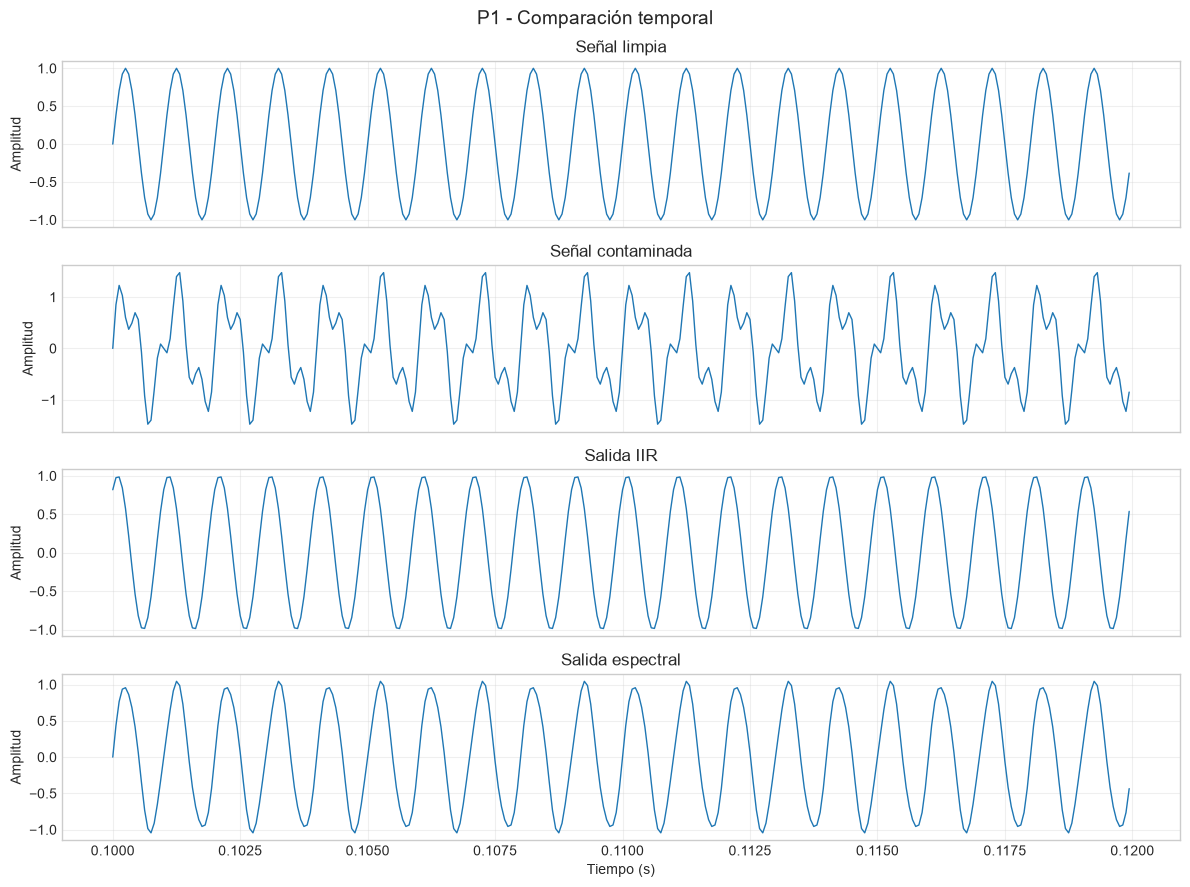

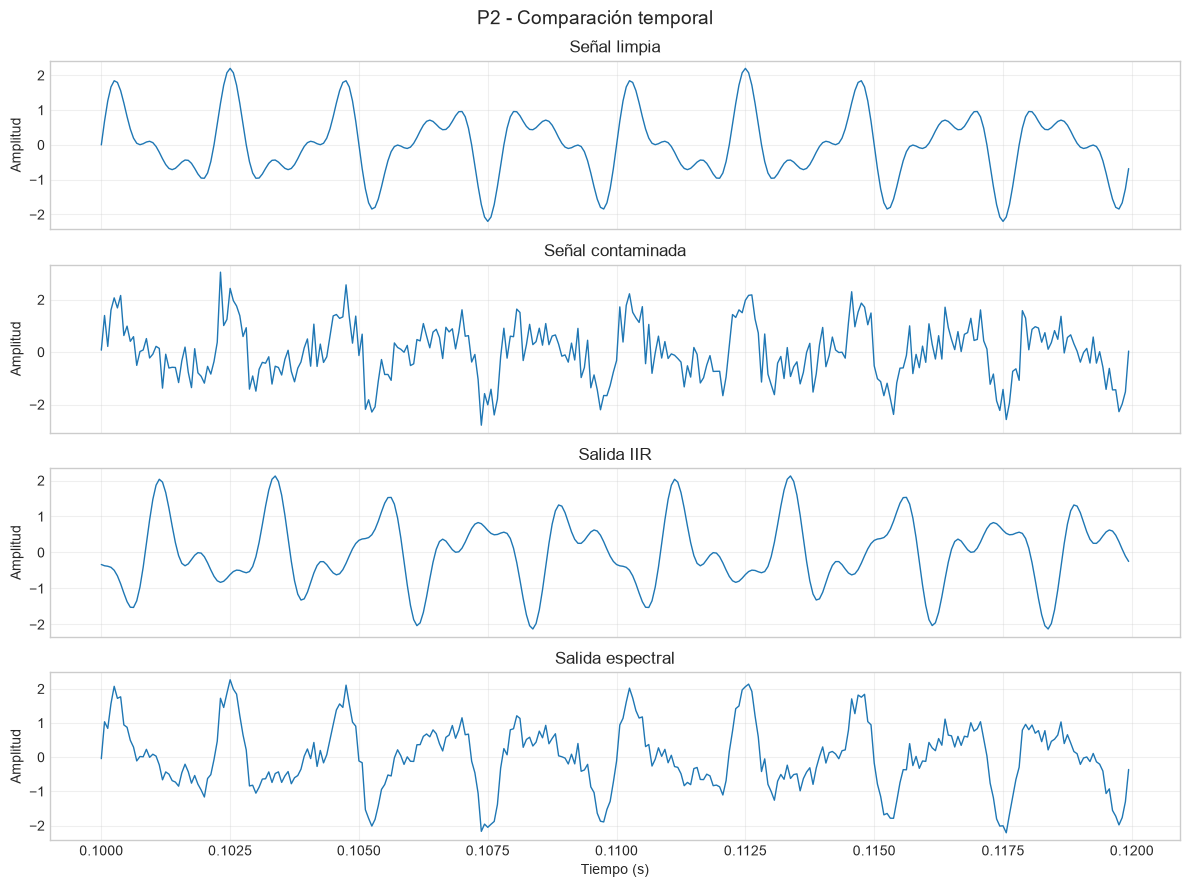

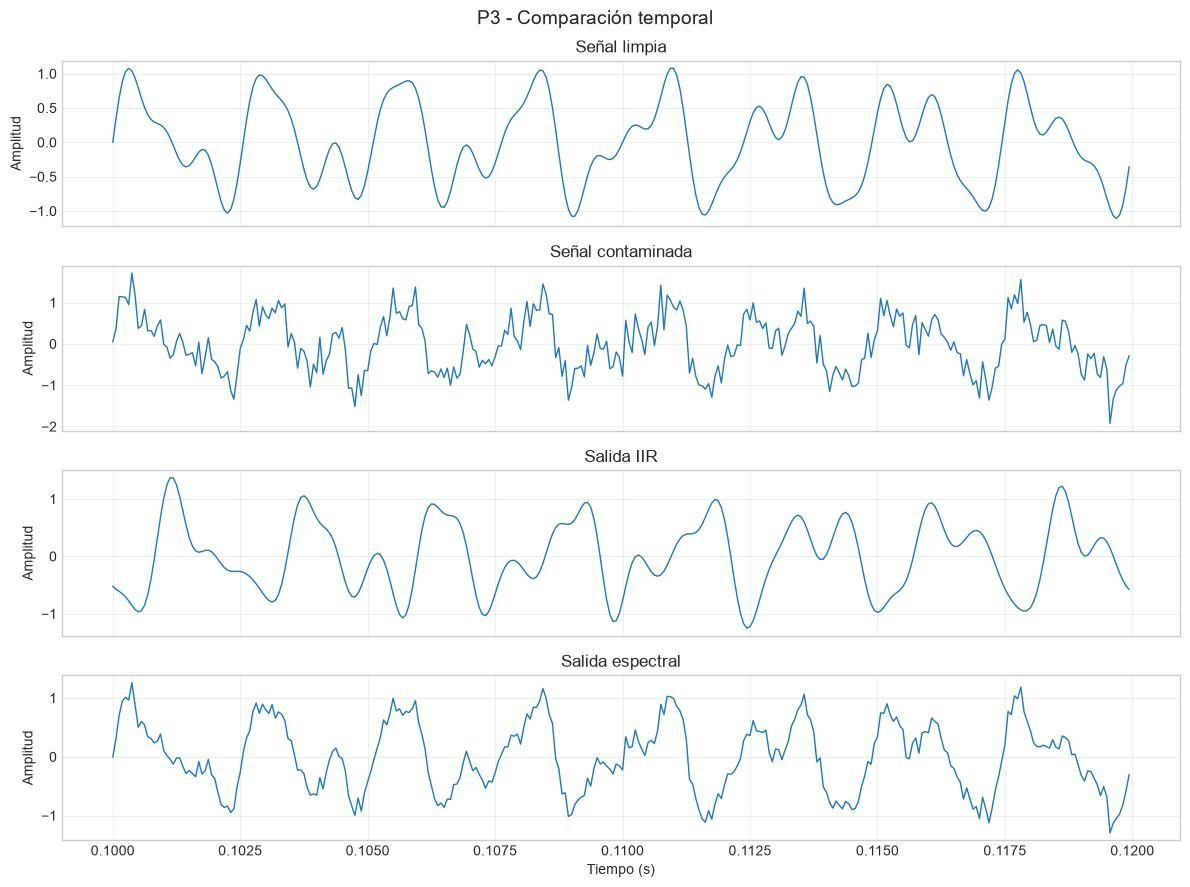

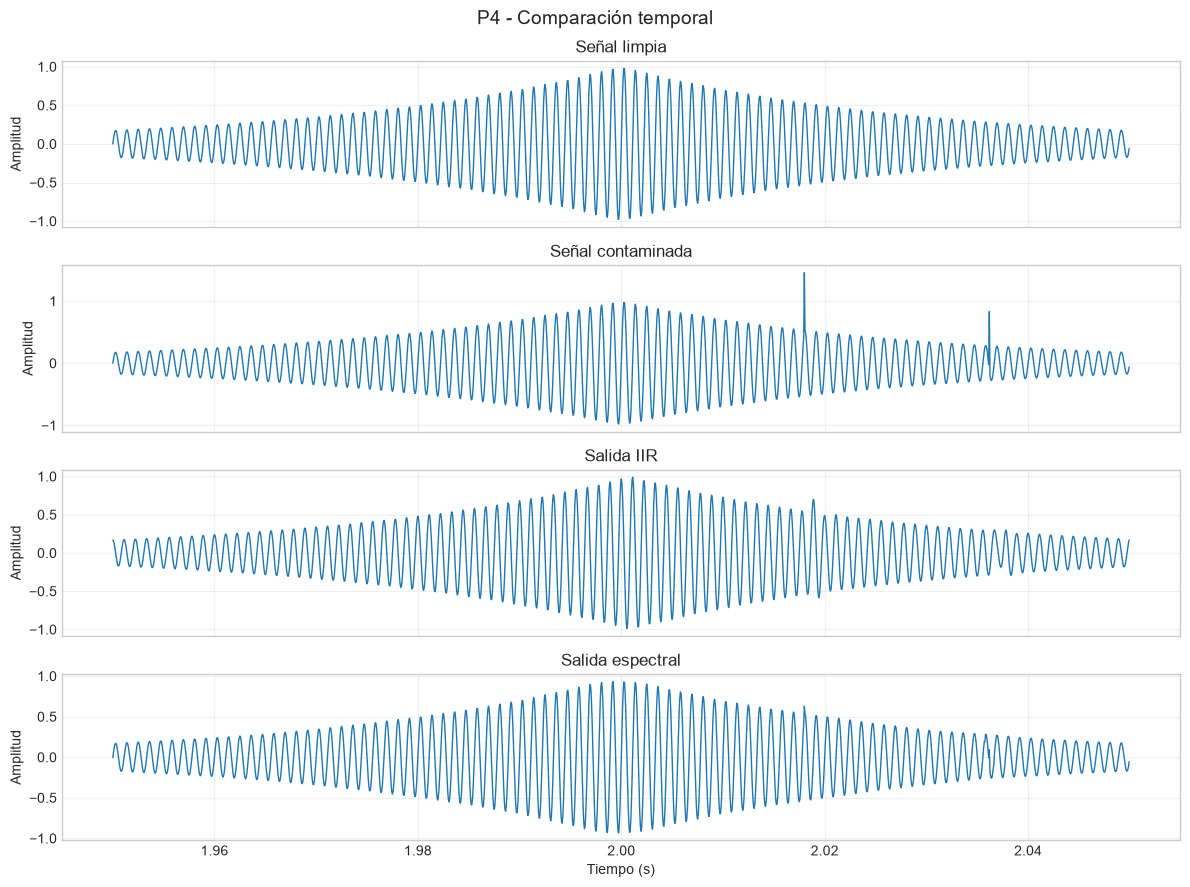

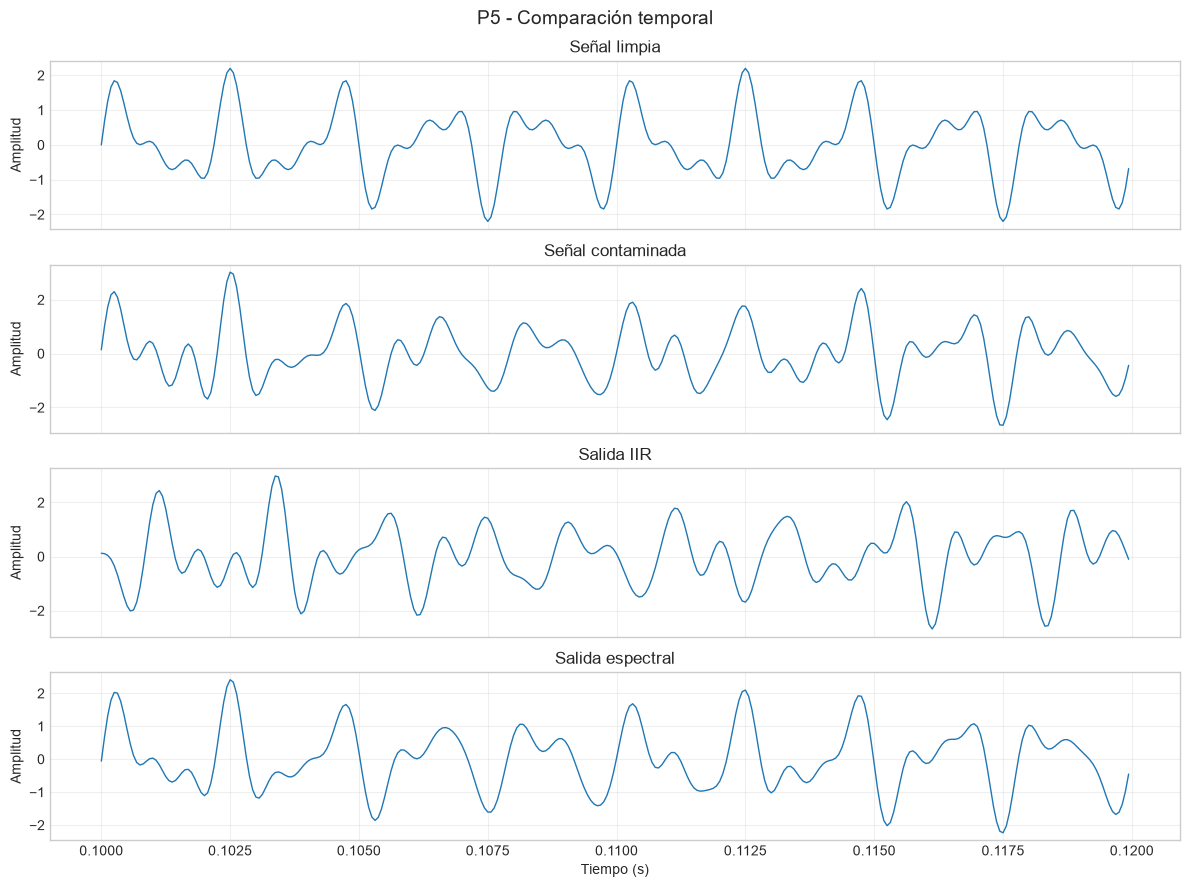

In [38]:

# =====================================================
# 12.3 COMPARACIÓN GRÁFICA
# =====================================================

FS_SIMULACION = 16000

for nombre, datos in resultados_simulacion.items():

    limpia = datos["limpia"]
    contaminada = datos["contaminada"]
    salida_iir = datos["iir"]
    salida_espectral = datos["espectral"]

    # -----------------------------------------
    # INTERVALO DE VISUALIZACIÓN
    # -----------------------------------------

    if nombre == "P4":
        tiempo_inicio = 1.95
        tiempo_fin = 2.05
    else:
        tiempo_inicio = 0.10
        tiempo_fin = 0.12

    inicio = int(tiempo_inicio * FS_SIMULACION)
    fin = int(tiempo_fin * FS_SIMULACION)

    tiempo = (
        np.arange(inicio, fin)
        / FS_SIMULACION
    )

    # -----------------------------------------
    # GRÁFICAS
    # -----------------------------------------

    fig, ejes = plt.subplots(
        4,
        1,
        figsize=(12, 9),
        sharex=True
    )

    senales = [
        ("Señal limpia", limpia),
        ("Señal contaminada", contaminada),
        ("Salida IIR", salida_iir),
        ("Salida espectral", salida_espectral),
    ]

    for eje, (titulo, senal) in zip(ejes, senales):

        eje.plot(
            tiempo,
            senal[inicio:fin],
            linewidth=1
        )

        eje.set_title(titulo)
        eje.set_ylabel("Amplitud")
        eje.grid(True, alpha=0.3)

    ejes[-1].set_xlabel("Tiempo (s)")

    fig.suptitle(
        f"{nombre} - Comparación temporal",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()



## 12.4 Alineación temporal para la evaluación cuantitativa

El filtrado IIR introduce un desfase entre la señal de referencia y la salida procesada.

Antes de calcular las métricas de desempeño, se estima el retardo mediante correlación cruzada y se alinean las señales para evitar que el desplazamiento temporal se interprete como error de reconstrucción.

La alineación se utiliza únicamente para la evaluación teórica y no modifica las señales originales almacenadas.


In [39]:

# =====================================================
# 12.4 ALINEACIÓN TEMPORAL
# =====================================================

from src.metricas import alinear_por_retardo

resultados_alineados = {}

for nombre, datos in resultados_simulacion.items():

    limpia = datos["limpia"]
    salida_iir = datos["iir"]
    salida_espectral = datos["espectral"]

    # -----------------------------------------
    # ALINEACIÓN DEL IIR CAUSAL
    # -----------------------------------------

    (
        limpia_iir,
        iir_alineada,
        retardo_iir
    ) = alinear_por_retardo(
        limpia,
        salida_iir,
        min_retardo=0,
        max_retardo=24
    )

    # -----------------------------------------
    # MÉTODO ESPECTRAL OFFLINE
    # -----------------------------------------

    limpia_espectral = limpia
    espectral_alineada = salida_espectral
    retardo_espectral = 0

    # -----------------------------------------
    # ALMACENAMIENTO
    # -----------------------------------------

    resultados_alineados[nombre] = {
        "limpia_iir": limpia_iir,
        "iir": iir_alineada,
        "retardo_iir": retardo_iir,
        "limpia_espectral": limpia_espectral,
        "espectral": espectral_alineada,
        "retardo_espectral": retardo_espectral,
    }

    print(
        nombre,
        "| Retardo IIR:",
        retardo_iir,
        "| Retardo espectral:",
        retardo_espectral
    )


P1 | Retardo IIR: 14 | Retardo espectral: 0
P2 | Retardo IIR: 14 | Retardo espectral: 0
P3 | Retardo IIR: 13 | Retardo espectral: 0
P4 | Retardo IIR: 13 | Retardo espectral: 0
P5 | Retardo IIR: 14 | Retardo espectral: 0



## 12.5 Evaluación cuantitativa de los métodos

Se calculan las métricas MSE, SNR de entrada, SNR de salida, mejora de SNR y energía útil proyectada para las pruebas P1–P5.

Para el método IIR se utilizan las señales alineadas mediante correlación cruzada, mientras que el método espectral se evalúa utilizando su alineación estimada.

La comparación se realiza sobre segmentos temporales equivalentes para cada método, evitando introducir diferencias por el recorte necesario durante la alineación.

Los resultados permiten evaluar la reducción de ruido y la distorsión introducida por cada estrategia.


In [40]:

# =====================================================
# 12.5 MÉTRICAS DE DESEMPEÑO
# =====================================================

import pandas as pd

from src.metricas import (
    calcular_mse,
    calcular_snr_db,
    energia_util_conservada_pct,
)


# =====================================================
# FUNCIÓN PARA OBTENER LA ENTRADA ALINEADA
# =====================================================

def obtener_entrada_alineada(entrada, retardo):

    if retardo > 0:
        return entrada[:-retardo]

    if retardo < 0:
        return entrada[-retardo:]

    return entrada


# =====================================================
# CÁLCULO DE MÉTRICAS
# =====================================================

filas_metricas = []

for nombre, datos in resultados_simulacion.items():

    alineados = resultados_alineados[nombre]

    contaminada = datos["contaminada"]

    for metodo in ["iir", "espectral"]:

        referencia = alineados[f"limpia_{metodo}"]
        salida = alineados[metodo]
        retardo = alineados[f"retardo_{metodo}"]

        entrada = obtener_entrada_alineada(
            contaminada,
            retardo
        )

        # Verificar longitudes
        assert len(referencia) == len(salida) == len(entrada)

        # MSE
        mse = calcular_mse(
            referencia,
            salida
        )

        # SNR de entrada
        snr_entrada = calcular_snr_db(
            referencia,
            entrada
        )

        # SNR de salida
        snr_salida = calcular_snr_db(
            referencia,
            salida
        )

        # Mejora de SNR
        delta_snr = snr_salida - snr_entrada

        # Energía útil proyectada
        energia = energia_util_conservada_pct(
            referencia,
            salida
        )

        filas_metricas.append({
            "Prueba": nombre,
            "Método": metodo.upper(),
            "MSE": mse,
            "SNR entrada (dB)": snr_entrada,
            "SNR salida (dB)": snr_salida,
            "Delta SNR (dB)": delta_snr,
            "Energía proyectada (%)": energia,
            "Retardo (muestras)": retardo,
        })


# =====================================================
# TABLA DE RESULTADOS
# =====================================================

tabla_metricas = pd.DataFrame(filas_metricas)

display(
    tabla_metricas.round(3)
)


,Prueba,Método,MSE,SNR entrada (dB),SNR salida (dB),Delta SNR (dB),Energía proyectada (%),Retardo (muestras)
0,P1,IIR,0.015,5.000,15.143,10.143,96.958,14
1,P1,ESPECTRAL,0.002,5.000,23.906,18.906,99.856,0
2,P2,IIR,0.050,5.000,12.375,7.375,93.929,14
3,P2,ESPECTRAL,0.037,5.000,13.675,8.675,99.773,0
4,P3,IIR,0.023,5.000,10.623,5.623,97.903,13
5,P3,ESPECTRAL,0.013,5.000,13.154,8.154,89.645,0
6,P4,IIR,0.000,5.000,11.354,6.354,98.872,13
7,P4,ESPECTRAL,0.000,5.000,19.673,14.673,98.095,0
8,P5,IIR,0.310,5.001,4.476,-0.525,95.205,14
9,P5,ESPECTRAL,0.084,5.000,10.139,5.139,85.301,0



## 12.6 Comparación gráfica de las métricas

Se presentan las métricas obtenidas para los métodos IIR y espectral en las pruebas P1–P5.

Se comparan el error cuadrático medio (MSE), la mejora de relación señal a ruido (ΔSNR) y la energía proyectada sobre la referencia limpia.

Las figuras se generan automáticamente a partir de la tabla de resultados, permitiendo visualizar el comportamiento de ambos métodos bajo diferentes condiciones de interferencia.



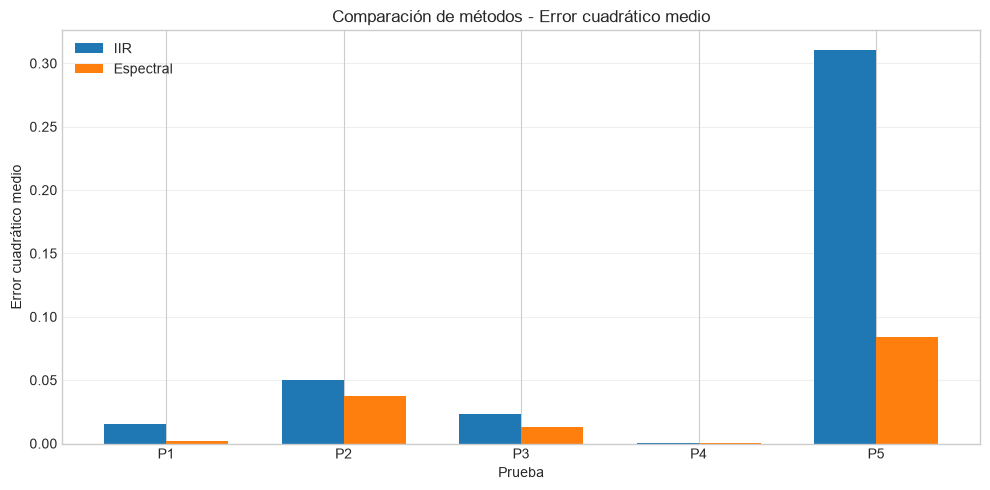

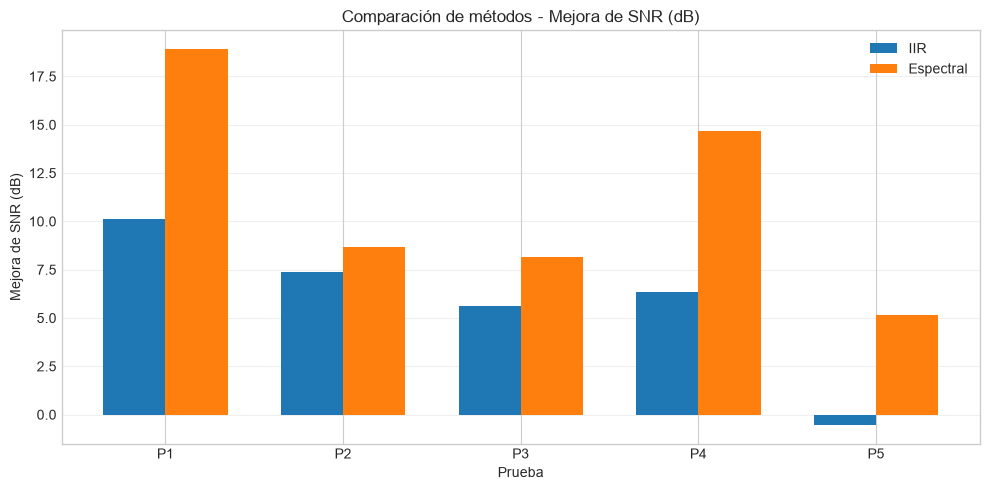

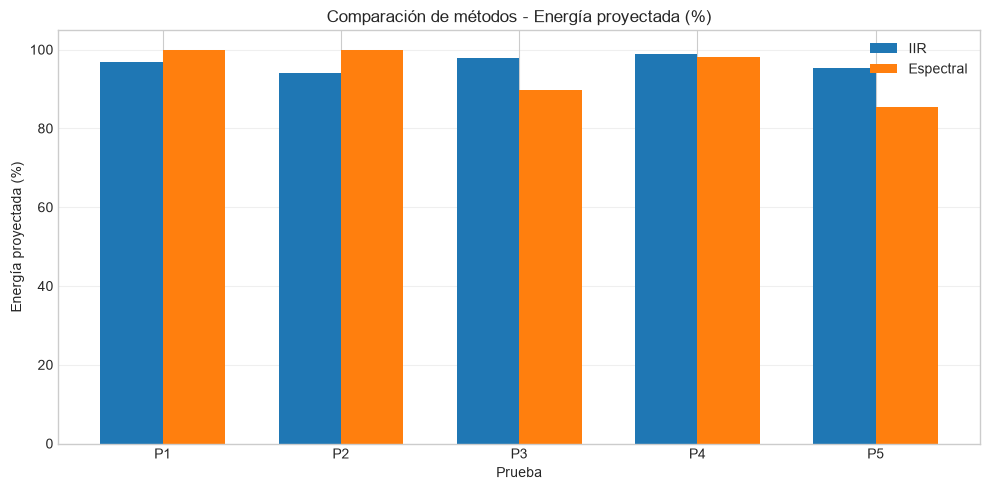

In [41]:

# =====================================================
# 12.6 GRÁFICAS COMPARATIVAS
# =====================================================

import matplotlib.pyplot as plt
import numpy as np

metricas_graficas = [
    ("MSE", "Error cuadrático medio"),
    ("Delta SNR (dB)", "Mejora de SNR (dB)"),
    ("Energía proyectada (%)", "Energía proyectada (%)"),
]

pruebas = ["P1", "P2", "P3", "P4", "P5"]

x = np.arange(len(pruebas))
ancho = 0.35

for columna, etiqueta in metricas_graficas:

    tabla_pivote = tabla_metricas.pivot(
        index="Prueba",
        columns="Método",
        values=columna
    ).reindex(pruebas)

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.bar(
        x - ancho / 2,
        tabla_pivote["IIR"],
        ancho,
        label="IIR"
    )

    ax.bar(
        x + ancho / 2,
        tabla_pivote["ESPECTRAL"],
        ancho,
        label="Espectral"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(pruebas)

    ax.set_ylabel(etiqueta)
    ax.set_xlabel("Prueba")

    ax.set_title(
        f"Comparación de métodos - {etiqueta}"
    )

    ax.legend()
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()



## 12.7 Exportación de gráficas y tablas

Se automatiza la exportación de los resultados de la simulación para su incorporación al artículo científico.

Las figuras comparativas se guardan en formatos PNG y PDF, mientras que las métricas se exportan en CSV.

Los archivos generados permiten reproducir las evidencias experimentales directamente a partir del notebook.


In [42]:

# =====================================================
# 12.7 EXPORTACIÓN AUTOMÁTICA DE RESULTADOS
# =====================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Directorio de salida
directorio_resultados = Path("resultados")
directorio_resultados.mkdir(
    parents=True,
    exist_ok=True
)

# =====================================================
# EXPORTAR TABLA
# =====================================================

ruta_csv = directorio_resultados / "metricas_simulacion.csv"

tabla_metricas.to_csv(
    ruta_csv,
    index=False
)

print("Tabla exportada:", ruta_csv)


# =====================================================
# EXPORTAR GRÁFICAS
# =====================================================

configuracion_graficas = [
    ("MSE", "Error cuadrático medio", "comparacion_mse"),
    ("Delta SNR (dB)", "Mejora de SNR (dB)", "comparacion_delta_snr"),
    ("Energía proyectada (%)", "Energía proyectada (%)", "comparacion_energia"),
]

pruebas = ["P1", "P2", "P3", "P4", "P5"]

x = np.arange(len(pruebas))
ancho = 0.35

for columna, etiqueta, nombre_archivo in configuracion_graficas:

    tabla_pivote = tabla_metricas.pivot(
        index="Prueba",
        columns="Método",
        values=columna
    ).reindex(pruebas)

    fig, ax = plt.subplots(
        figsize=(9, 5)
    )

    ax.bar(
        x - ancho / 2,
        tabla_pivote["IIR"],
        ancho,
        label="IIR"
    )

    ax.bar(
        x + ancho / 2,
        tabla_pivote["ESPECTRAL"],
        ancho,
        label="Espectral"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(pruebas)

    ax.set_xlabel("Prueba")
    ax.set_ylabel(etiqueta)
    ax.set_title(etiqueta)

    ax.legend()
    ax.grid(axis="y", alpha=0.3)

    fig.tight_layout()

    # Exportar PNG
    fig.savefig(
        directorio_resultados / f"{nombre_archivo}.png",
        dpi=300,
        bbox_inches="tight"
    )

    # Exportar PDF
    fig.savefig(
        directorio_resultados / f"{nombre_archivo}.pdf",
        bbox_inches="tight"
    )

    plt.close(fig)

    print("Figura exportada:", nombre_archivo)

print()
print("Exportación completada.")


Tabla exportada: resultados\metricas_simulacion.csv
Figura exportada: comparacion_mse
Figura exportada: comparacion_delta_snr
Figura exportada: comparacion_energia

Exportación completada.



## 12.8 Preparación de las repeticiones experimentales

Se incorporan semillas configurables para realizar diferentes realizaciones de ruido en las pruebas P1–P5.

Cada prueba conserva su señal útil, frecuencia de muestreo y SNR inicial objetivo de 5 dB. Las semillas permiten variar de manera reproducible las interferencias y evaluar la variabilidad de los métodos de filtrado.

En P1 se modifica la fase de la interferencia sinusoidal. En las pruebas P2–P5 se generan distintas realizaciones del ruido correspondiente.


In [43]:

# =====================================================
# 12.8 VERIFICACIÓN DE SEMILLAS
# =====================================================

from src.senales import (
    generar_p1,
    generar_p2,
    generar_p3,
    generar_p4,
    generar_p5,
)

generadores = {
    "P1": generar_p1,
    "P2": generar_p2,
    "P3": generar_p3,
    "P4": generar_p4,
    "P5": generar_p5,
}

for nombre, generar in generadores.items():

    limpia_1, ruido_1, contaminada_1 = generar(
        semilla=1001
    )

    limpia_2, ruido_2, contaminada_2 = generar(
        semilla=1002
    )

    misma_senal = np.array_equal(
        limpia_1,
        limpia_2
    )

    ruido_diferente = not np.array_equal(
        ruido_1,
        ruido_2
    )

    snr_1 = calcular_snr_db(
        limpia_1,
        contaminada_1
    )

    snr_2 = calcular_snr_db(
        limpia_2,
        contaminada_2
    )

    print(
        nombre,
        "| Señal útil igual:",
        misma_senal,
        "| Ruido diferente:",
        ruido_diferente,
        "| SNR:",
        f"{snr_1:.3f}",
        f"{snr_2:.3f}",
        "dB"
    )


P1 | Señal útil igual: True | Ruido diferente: True | SNR: 5.000 5.000 dB
P2 | Señal útil igual: True | Ruido diferente: True | SNR: 5.000 5.000 dB
P3 | Señal útil igual: True | Ruido diferente: True | SNR: 5.000 5.000 dB
P4 | Señal útil igual: True | Ruido diferente: True | SNR: 5.000 5.000 dB
P5 | Señal útil igual: True | Ruido diferente: True | SNR: 5.000 5.000 dB



## 12.9 Ejecución de repeticiones experimentales

Se realizan tres repeticiones independientes de las pruebas P1–P5, utilizando diferentes semillas para generar realizaciones reproducibles del ruido.

Cada señal contaminada se procesa mediante los métodos IIR y espectral, conservando los mismos parámetros de filtrado establecidos anteriormente.

Para cada ejecución se calculan el MSE, SNR de entrada, SNR de salida y mejora de SNR. Los resultados individuales se almacenan para calcular posteriormente sus promedios y desviaciones estándar.

La alineación temporal del IIR se realiza utilizando el procedimiento definido en el módulo de métricas, mientras que la salida espectral conserva la referencia temporal de la simulación offline.


In [44]:

# =====================================================
# 12.9 REPETICIONES EXPERIMENTALES
# =====================================================

import numpy as np
import pandas as pd

from src.metricas import (
    calcular_mse,
    calcular_snr_db,
    alinear_por_retardo,
)


# =====================================================
# CONFIGURACIÓN
# =====================================================

semillas_repeticiones = [1001, 1002, 1003]

resultados_repeticiones = []


# =====================================================
# EJECUTAR PRUEBAS P1-P5
# =====================================================

for nombre, generar in generadores.items():

    for repeticion, semilla in enumerate(
        semillas_repeticiones,
        start=1
    ):

        # -----------------------------------------
        # GENERACIÓN DE SEÑALES
        # -----------------------------------------

        limpia, ruido, contaminada = generar(
            semilla=semilla
        )

        # -----------------------------------------
        # FILTRADO IIR
        # -----------------------------------------

        salida_iir = filtrar_iir(
            contaminada,
            sos_simulacion
        )

        (
            limpia_iir,
            iir_alineada,
            retardo_iir
        ) = alinear_por_retardo(
            limpia,
            salida_iir,
            min_retardo=0,
            max_retardo=24
        )

        # Entrada correspondiente al segmento
        # de referencia utilizado por el IIR.
        entrada_iir = contaminada[
            :len(limpia_iir)
        ]

        # -----------------------------------------
        # FILTRADO ESPECTRAL
        # -----------------------------------------

        salida_espectral = filtrar_espectral(
            contaminada
        )

        # En la simulación offline, la salida
        # espectral conserva la referencia temporal.
        limpia_espectral = limpia
        entrada_espectral = contaminada

        # -----------------------------------------
        # EVALUACIÓN DE AMBOS MÉTODOS
        # -----------------------------------------

        metodos = {
            "IIR": (
                limpia_iir,
                entrada_iir,
                iir_alineada,
                retardo_iir
            ),
            "ESPECTRAL": (
                limpia_espectral,
                entrada_espectral,
                salida_espectral,
                0
            )
        }

        for metodo, valores in metodos.items():

            referencia, entrada, salida, retardo = valores

            assert (
                len(referencia)
                == len(entrada)
                == len(salida)
            )

            mse = calcular_mse(
                referencia,
                salida
            )

            snr_entrada = calcular_snr_db(
                referencia,
                entrada
            )

            snr_salida = calcular_snr_db(
                referencia,
                salida
            )

            delta_snr = (
                snr_salida - snr_entrada
            )

            resultados_repeticiones.append({
                "Prueba": nombre,
                "Repetición": repeticion,
                "Semilla": semilla,
                "Método": metodo,
                "MSE": mse,
                "SNR entrada (dB)": snr_entrada,
                "SNR salida (dB)": snr_salida,
                "Delta SNR (dB)": delta_snr,
                "Retardo (muestras)": retardo,
            })


# =====================================================
# TABLA DE RESULTADOS
# =====================================================

tabla_repeticiones = pd.DataFrame(
    resultados_repeticiones
)

print("REPETICIONES EXPERIMENTALES")
print("Pruebas:", tabla_repeticiones["Prueba"].nunique())
print("Repeticiones por prueba:", len(semillas_repeticiones))
print("Evaluaciones:", len(tabla_repeticiones))

print()

display(
    tabla_repeticiones.round(4)
)


REPETICIONES EXPERIMENTALES
Pruebas: 5
Repeticiones por prueba: 3
Evaluaciones: 30



,Prueba,Repetición,Semilla,Método,MSE,SNR entrada (dB),SNR salida (dB),Delta SNR (dB),Retardo (muestras)
0,P1,1,1001,IIR,0.0153,4.9999,15.1434,10.1435,14
1,P1,1,1001,ESPECTRAL,0.0020,5.0000,23.9048,18.9048,0
2,P1,2,1002,IIR,0.0153,5.0000,15.1431,10.1432,14
3,P1,2,1002,ESPECTRAL,0.0020,5.0000,23.9001,18.9001,0
4,P1,3,1003,IIR,0.0153,4.9999,15.1429,10.1430,14
5,P1,3,1003,ESPECTRAL,0.0020,5.0000,23.9022,18.9022,0
6,P2,1,1001,IIR,0.0503,4.9996,12.3753,7.3757,14
7,P2,1,1001,ESPECTRAL,0.0371,5.0000,13.7055,8.7055,0
8,P2,2,1002,IIR,0.0503,5.0000,12.3753,7.3753,14
9,P2,2,1002,ESPECTRAL,0.0374,5.0000,13.6703,8.6703,0



## 12.10 Análisis estadístico de las repeticiones

A partir de las tres repeticiones experimentales de P1–P5, se calculan los promedios y las desviaciones estándar muestrales de las métricas de desempeño.

Se consideran el error cuadrático medio (MSE), la relación señal a ruido (SNR) de entrada y salida, y la mejora de SNR (ΔSNR).

Los resultados permiten comparar el desempeño promedio de los métodos temporal y espectral, así como la variabilidad observada ante distintas realizaciones del ruido.

Las desviaciones estándar se calculan con un grado de libertad de corrección (ddof = 1), correspondiente a la desviación estándar muestral.


In [45]:

# =====================================================
# 12.10 ANÁLISIS ESTADÍSTICO
# =====================================================

# =====================================================
# MÉTRICAS A ANALIZAR
# =====================================================

columnas_metricas = [
    "MSE",
    "SNR entrada (dB)",
    "SNR salida (dB)",
    "Delta SNR (dB)",
]


# =====================================================
# PROMEDIOS Y DESVIACIONES ESTÁNDAR
# =====================================================

tabla_estadisticas = (
    tabla_repeticiones
    .groupby(["Prueba", "Método"])[columnas_metricas]
    .agg(["mean", "std"])
    .reset_index()
)


# =====================================================
# ORGANIZAR NOMBRES DE COLUMNAS
# =====================================================

tabla_estadisticas.columns = [
    "Prueba",
    "Método",
    "MSE promedio",
    "MSE desviación",
    "SNR entrada promedio (dB)",
    "SNR entrada desviación (dB)",
    "SNR salida promedio (dB)",
    "SNR salida desviación (dB)",
    "Delta SNR promedio (dB)",
    "Delta SNR desviación (dB)",
]


# =====================================================
# MOSTRAR RESULTADOS
# =====================================================

print("ESTADÍSTICAS DE LAS REPETICIONES")
print("Número de repeticiones:", len(semillas_repeticiones))
print("Combinaciones evaluadas:", len(tabla_estadisticas))

print()

display(
    tabla_estadisticas.round(5)
)


ESTADÍSTICAS DE LAS REPETICIONES
Número de repeticiones: 3
Combinaciones evaluadas: 10



,Prueba,Método,MSE promedio,MSE desviación,SNR entrada promedio (dB),SNR entrada desviación (dB),SNR salida promedio (dB),SNR salida desviación (dB),Delta SNR promedio (dB),Delta SNR desviación (dB)
0,P1,ESPECTRAL,0.00204,0.00000,5.00000,0.00000,23.90238,0.00235,18.90238,0.00235
1,P1,IIR,0.01530,0.00000,4.99991,0.00005,15.14315,0.00024,10.14324,0.00025
2,P2,ESPECTRAL,0.03701,0.00038,5.00000,0.00000,13.71175,0.04492,8.71175,0.04492
3,P2,IIR,0.05035,0.00000,4.99980,0.00018,12.37528,0.00003,7.37548,0.00018
4,P3,ESPECTRAL,0.01289,0.00008,5.00000,0.00000,13.16363,0.02803,8.16363,0.02803
5,P3,IIR,0.02314,0.00012,5.00024,0.00015,10.62346,0.02329,5.62322,0.02336
6,P4,ESPECTRAL,0.00002,0.00000,5.00000,0.00000,20.61155,0.41570,15.61155,0.41570
7,P4,IIR,0.00018,0.00000,5.00000,0.00000,11.27635,0.04689,6.27635,0.04689
8,P5,ESPECTRAL,0.08700,0.00086,5.00000,0.00000,9.99996,0.04295,4.99996,0.04295
9,P5,IIR,0.30940,0.00091,4.99936,0.00012,4.48976,0.01283,-0.50960,0.01272



## 12.11 Comparación estadística de los métodos

Se representan gráficamente los promedios y las desviaciones estándar muestrales obtenidos mediante tres repeticiones de las pruebas P1–P5.

Se incluyen el error cuadrático medio (MSE), la SNR de salida y la mejora de SNR (ΔSNR). Las barras de error representan una desviación estándar por encima y por debajo del promedio.

Estas figuras permiten comparar los métodos temporal y espectral, considerando tanto su rendimiento como la variabilidad observada entre diferentes realizaciones del ruido.


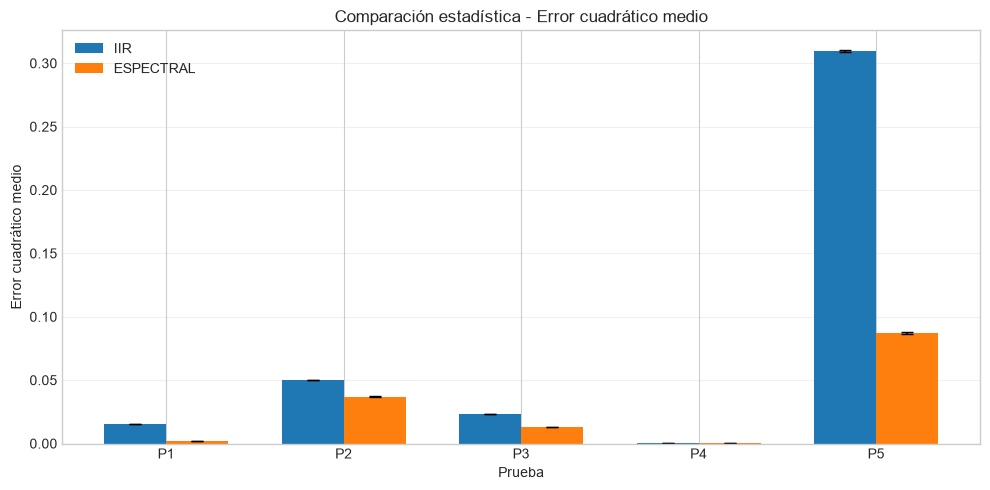

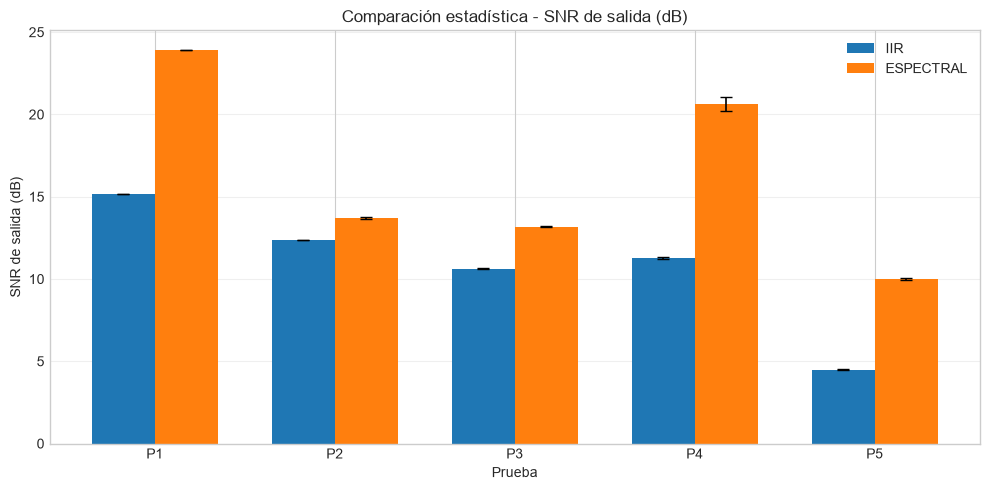

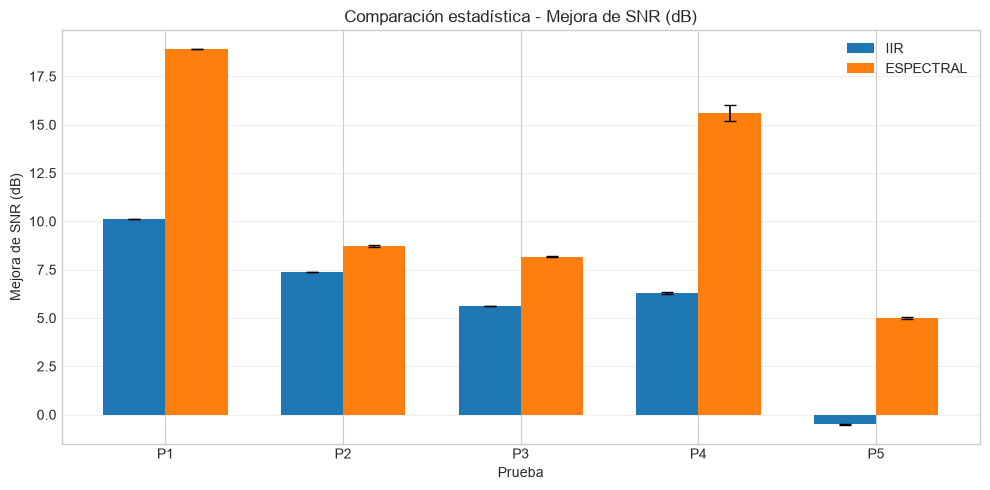

In [46]:

# =====================================================
# 12.11 GRÁFICAS ESTADÍSTICAS
# =====================================================

import numpy as np
import matplotlib.pyplot as plt

configuracion_estadisticas = [
    (
        "MSE promedio",
        "MSE desviación",
        "Error cuadrático medio",
    ),
    (
        "SNR salida promedio (dB)",
        "SNR salida desviación (dB)",
        "SNR de salida (dB)",
    ),
    (
        "Delta SNR promedio (dB)",
        "Delta SNR desviación (dB)",
        "Mejora de SNR (dB)",
    ),
]

pruebas = ["P1", "P2", "P3", "P4", "P5"]

x = np.arange(len(pruebas))
ancho = 0.35

for columna_promedio, columna_desviacion, etiqueta in configuracion_estadisticas:

    fig, ax = plt.subplots(figsize=(10, 5))

    for metodo, desplazamiento in [
        ("IIR", -ancho / 2),
        ("ESPECTRAL", ancho / 2),
    ]:

        datos = (
            tabla_estadisticas[
                tabla_estadisticas["Método"] == metodo
            ]
            .set_index("Prueba")
            .reindex(pruebas)
        )

        ax.bar(
            x + desplazamiento,
            datos[columna_promedio],
            ancho,
            yerr=datos[columna_desviacion],
            capsize=4,
            label=metodo,
            error_kw={"elinewidth": 1.2}
        )

    ax.set_xticks(x)
    ax.set_xticklabels(pruebas)

    ax.set_xlabel("Prueba")
    ax.set_ylabel(etiqueta)

    ax.set_title(
        f"Comparación estadística - {etiqueta}"
    )

    ax.legend()
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()



## 12.12 Exportación de resultados estadísticos

Se exportan los resultados individuales de las tres repeticiones y las estadísticas descriptivas correspondientes a las pruebas P1–P5.

Las gráficas de MSE, SNR de salida y mejora de SNR se almacenan en formatos PNG y PDF, incluyendo barras de error correspondientes a una desviación estándar muestral.

Estos archivos proporcionan evidencias reproducibles para la sección de resultados y análisis del artículo científico.


In [47]:

# =====================================================
# 12.12 EXPORTACIÓN DE RESULTADOS ESTADÍSTICOS
# =====================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

directorio_resultados = Path("resultados")

directorio_resultados.mkdir(
    parents=True,
    exist_ok=True
)


# =====================================================
# EXPORTAR TABLAS
# =====================================================

tabla_repeticiones.to_csv(
    directorio_resultados / "repeticiones_simulacion.csv",
    index=False
)

tabla_estadisticas.to_csv(
    directorio_resultados / "estadisticas_simulacion.csv",
    index=False
)

print("Tablas estadísticas exportadas.")


# =====================================================
# CONFIGURACIÓN DE FIGURAS
# =====================================================

configuracion_exportacion = [
    (
        "MSE promedio",
        "MSE desviación",
        "Error cuadrático medio",
        "estadisticas_mse"
    ),
    (
        "SNR salida promedio (dB)",
        "SNR salida desviación (dB)",
        "SNR de salida (dB)",
        "estadisticas_snr_salida"
    ),
    (
        "Delta SNR promedio (dB)",
        "Delta SNR desviación (dB)",
        "Mejora de SNR (dB)",
        "estadisticas_delta_snr"
    ),
]

pruebas = ["P1", "P2", "P3", "P4", "P5"]

x = np.arange(len(pruebas))
ancho = 0.35


# =====================================================
# GENERAR Y EXPORTAR
# =====================================================

for promedio, desviacion, etiqueta, archivo in configuracion_exportacion:

    fig, ax = plt.subplots(figsize=(9, 5))

    for metodo, desplazamiento in [
        ("IIR", -ancho / 2),
        ("ESPECTRAL", ancho / 2)
    ]:

        datos = (
            tabla_estadisticas[
                tabla_estadisticas["Método"] == metodo
            ]
            .set_index("Prueba")
            .reindex(pruebas)
        )

        ax.bar(
            x + desplazamiento,
            datos[promedio],
            ancho,
            yerr=datos[desviacion],
            capsize=4,
            label=metodo
        )

    ax.set_xticks(x)
    ax.set_xticklabels(pruebas)

    ax.set_xlabel("Prueba")
    ax.set_ylabel(etiqueta)
    ax.set_title(etiqueta)

    ax.legend()
    ax.grid(axis="y", alpha=0.3)

    fig.tight_layout()

    # PNG de alta resolución
    fig.savefig(
        directorio_resultados / f"{archivo}.png",
        dpi=300,
        bbox_inches="tight"
    )

    # PDF vectorial
    fig.savefig(
        directorio_resultados / f"{archivo}.pdf",
        bbox_inches="tight"
    )

    plt.close(fig)

    print("Figura exportada:", archivo)

print()
print("Exportación estadística completada.")


Tablas estadísticas exportadas.
Figura exportada: estadisticas_mse
Figura exportada: estadisticas_snr_salida
Figura exportada: estadisticas_delta_snr

Exportación estadística completada.
